# AgentShield ML notebook

This is the one notebook for all the ML work in AgentShield (as the PRD asks): a prompt-injection detector, a similarity checker for agent responses, and an anomaly detector for agent telemetry.

- prompt injection: TF-IDF + logistic regression baseline first, then DistilBERT (section 06)
- response similarity: all-MiniLM-L6-v2, used as it is, no fine-tuning (section 07)
- anomaly detection: Isolation Forest (section 08)

A few ground rules I'm following. Every number in the final report is computed by a cell that actually ran, nothing is typed in by hand. If a step can't run (no GPU, no route to Hugging Face, etc.) it gets marked SKIPPED with the reason, and I don't swap in some other model to fill the gap. Every data source records where it came from and what its licence is, and synthetic data is always labelled synthetic.

Some steps need Hugging Face (the deepset and neuralchemy datasets, STS-B, the model weights). If the Hub isn't reachable those parts are skipped, and the run status table at the end shows exactly what ran and what didn't.

## 01. Setup

In [1]:
# Imports
import os, sys, json, re, gc, time, math, random, hashlib, platform, unicodedata
import warnings, shutil, importlib, zipfile, io, urllib.request, urllib.error, traceback
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg") if os.environ.get("MPLBACKEND") == "Agg" else None
import matplotlib.pyplot as plt
import joblib

import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve, mean_squared_error,
                             mean_absolute_error)
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from scipy.stats import pearsonr, spearmanr

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

def now_iso():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__)

python 3.12.3 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1


In [2]:
# Configuration (every knob that affects results lives here)
CONFIG = {
    "SEED": 42,
    "MODEL_VERSION": "0.1.0",

    # data
    "BIPIA_REPO": "microsoft/BIPIA",
    "BIPIA_COMMIT": "a004b69ec0dd446e0afd461d98cb5e96e120a5d0",   # pinned; audited 2026-11-05
    "BIPIA_TASKS": ["email", "table", "code"],    # qa/abstract need outside corpora, skipped
    "BIPIA_MAX_CONTEXTS_PER_TASK_SPLIT": 300,     # cap so one task cannot dominate
    "BIPIA_CROP_CHARS": 500,                      # characters kept each side of the insertion point
    "BIPIA_VAL_CONTEXT_FRAC": 0.20,               # fraction of train contexts held out for validation
    "BIPIA_VAL_CATEGORY_FRAC": 0.20,              # same, for attack categories
    "BIPIA_CTX_NEAR_DUP_THRESHOLD": 0.80,         # above this cosine = same document

    "HF_PROMPT_SOURCES": {
        # key -> hub repo id and config name
        "deepset_prompt_injections":     {"repo": "deepset/prompt-injections",               "config": None},
        "neuralchemy_prompt_injection":  {"repo": "neuralchemy/Prompt-injection-dataset",     "config": None},
    },
    "HF_STSB": {"repo": "nyu-mll/glue", "config": "stsb"},
    "HF_MINILM": "sentence-transformers/all-MiniLM-L6-v2",
    "HF_DISTILBERT": "distilbert-base-uncased",

    # licences allowed for training; anything else is excluded unless overridden
    "LICENSE_ALLOWLIST": ["mit", "apache-2.0", "bsd-3-clause", "bsd-2-clause", "cc0-1.0", "cc-by-4.0",
                          "cc-by-3.0", "cc-by-sa-4.0", "cc-by-sa-3.0", "odc-by", "cdla-permissive-2.0"],
    "ALLOW_UNVERIFIED_LICENSE": False,

    # cleaning and splitting
    "NEAR_DUP_THRESHOLD": 0.90,     # cosine on word 1-2gram TF-IDF
    "SPLIT_FRACTIONS": {"train": 5/7, "val": 1/7, "test": 1/7},   # ~70/15/15 via 7 stratified folds

    # prompt injection models
    "PI_THRESHOLD_STRATEGY": "max_f1",     # "max_f1" or "recall_floor"
    "PI_RECALL_FLOOR": 0.95,
    "PI_LR_C_GRID": [0.1, 1.0, 10.0, 100.0],
    "PI_DISTILBERT": {"max_len": 384, "epochs": 3, "lr": 2e-5, "weight_decay": 0.01, "warmup_ratio": 0.1,
                      "batch_gpu": 16, "batch_cpu": 8, "grad_clip": 1.0, "use_class_weights": True,
                      "resume": True, "max_cpu_train_samples": 2000},

    # semantic similarity
    "STS_POSITIVE_GOLD_CUTOFF": 4.0,       # gold >= 4 out of 5 counts as "same meaning"
    "STS_ENCODE_BATCH": 64,

    # anomaly detection
    "AD_SYNTH_N": 6000,
    "AD_SYNTH_ANOMALY_RATE": 0.03,
    "AD_MIN_REAL_ROWS": 500,
    "AD_DB_ENV_VAR": "AGENTSHIELD_DB_URL",
}

# Paths
def find_ml_root() -> Path:
    env = os.environ.get("AGENTSHIELD_ML_ROOT")
    if env:
        return Path(env).resolve()
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if p.name == "ml" and (p / "notebooks").exists():
            return p
        if (p / "ml" / "notebooks").exists():
            return p / "ml"
    raise RuntimeError("Cannot locate the ml/ directory. Set AGENTSHIELD_ML_ROOT.")

ML_ROOT   = find_ml_root()
RAW       = ML_ROOT / "datasets" / "raw"
PROCESSED = ML_ROOT / "datasets" / "processed"
METADATA  = ML_ROOT / "datasets" / "metadata"
ARTIFACTS = ML_ROOT / "artifacts"
REP_EVAL  = ML_ROOT / "reports" / "evaluation"
REP_VIZ   = ML_ROOT / "reports" / "visualizations"
for d in (RAW, PROCESSED, METADATA, ARTIFACTS, REP_EVAL, REP_VIZ):
    d.mkdir(parents=True, exist_ok=True)
print("ML_ROOT =", ML_ROOT)

ML_ROOT = /home/claude/AgentShield-AI-v1/ml


In [3]:
# Seeds, device detection, optional dependencies
SEED = CONFIG["SEED"]
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)

def _try_import(name):
    try:
        return importlib.import_module(name)
    except Exception:
        return None

torch         = _try_import("torch")
transformers  = _try_import("transformers")
hf_datasets   = _try_import("datasets")
hf_hub        = _try_import("huggingface_hub")
st_lib        = _try_import("sentence_transformers")
sqlalchemy    = _try_import("sqlalchemy")

HAVE_TORCH, HAVE_TRANSFORMERS = torch is not None, transformers is not None
HAVE_DATASETS, HAVE_HUB, HAVE_ST = hf_datasets is not None, hf_hub is not None, st_lib is not None

if HAVE_TORCH:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else None
else:
    DEVICE, GPU_NAME = "cpu", None
USE_AMP = (DEVICE == "cuda")

def hf_reachable(timeout=6) -> bool:
    try:
        urllib.request.urlopen(urllib.request.Request("https://huggingface.co", method="HEAD"), timeout=timeout)
        return True
    except Exception:
        return False
HF_OK = hf_reachable()

ENV_INFO = {
    "python": platform.python_version(), "platform": platform.platform(),
    "torch": getattr(torch, "__version__", None), "transformers": getattr(transformers, "__version__", None),
    "datasets": getattr(hf_datasets, "__version__", None),
    "sentence_transformers": getattr(st_lib, "__version__", None),
    "sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__,
    "device": DEVICE, "gpu": GPU_NAME, "amp": USE_AMP, "huggingface_hub_reachable": HF_OK,
}
print(json.dumps(ENV_INFO, indent=2))

# these collect results as we go; the report at the end reads them
SOURCES: list = []          # one dict per data source
RESULTS: dict = {}          # metrics, by component
STATUS: dict = {}           # component -> state + reason
BLOCKERS: list = []         # human-readable blockers
CLEAN_LOG: dict = {}        # cleaning decisions with counts

def set_status(component, state, reason=""):
    STATUS[component] = {"state": state, "reason": reason}
    if state in ("SKIPPED", "PARTIAL") and reason:
        BLOCKERS.append(f"[{component}] {state}: {reason}")
    print(f"STATUS  {component:<34s} {state}  {reason}")

def jsonable(o):
    if isinstance(o, dict):  return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)): return [jsonable(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, np.ndarray): return jsonable(o.tolist())
    if isinstance(o, (pd.Timestamp, datetime)): return o.isoformat()
    if isinstance(o, Path): return str(o)
    if isinstance(o, float) and math.isnan(o): return None
    return o

if not HF_OK:
    print("\nNOTE: huggingface.co is not reachable from this environment. Hub-dependent steps will be "
          "skipped and recorded as blockers.")

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "python": "3.12.3",
  "platform": "Linux-6.18.44-fc-v236-x86_64-with-glibc2.39",
  "torch": null,
  "transformers": null,
  "datasets": "5.1.0",
  "sentence_transformers": null,
  "sklearn": "1.9.1",
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "device": "cpu",
  "gpu": null,
  "amp": false,
  "huggingface_hub_reachable": false
}

NOTE: huggingface.co is not reachable from this environment. Hub-dependent steps will be skipped and recorded as blockers.


## 02. Getting the data

Sources:

- **BIPIA** (microsoft/BIPIA): indirect prompt injection. Downloaded from GitHub at a pinned commit, so it works without Hugging Face. The licence is read from the repo's LICENSE and NOTICE files.
- **deepset/prompt-injections** and **neuralchemy/Prompt-injection-dataset**: normal prompts and direct injections. These come from the Hugging Face Hub, and the licence is read from the dataset card when the notebook runs.
- **GLUE STS-B**: human-scored sentence pairs (0 to 5) for the similarity part.

I left out BIPIA's `qa` and `abstract` tasks because they need NewsQA and XSum, which have to be downloaded from their owners under their own terms.

The first successful download pins the exact revision in `datasets/metadata/sources_lock.json`, so later runs load the same data. A dataset whose licence is missing or not on the allow-list is skipped unless you flip the override in CONFIG.

In [4]:
# Lock file + source registry helpers
LOCK_PATH = METADATA / "sources_lock.json"
LOCK = json.loads(LOCK_PATH.read_text()) if LOCK_PATH.exists() else {}

def save_lock():
    LOCK_PATH.write_text(json.dumps(LOCK, indent=2, sort_keys=True))

def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def license_ok(lic) -> tuple:
    """(allowed_for_training, normalized_license_string)"""
    if lic is None:
        return False, "UNKNOWN"
    if isinstance(lic, (list, tuple)):
        lic = ",".join(str(x) for x in lic)
    lic_n = str(lic).strip().lower()
    parts = [p.strip() for p in re.split(r"[,;/ ]+", lic_n) if p.strip()]
    ok = len(parts) > 0 and all(p in CONFIG["LICENSE_ALLOWLIST"] for p in parts)
    return ok, lic_n or "UNKNOWN"

def pinned_revision(repo, kind="model"):
    """Revision (commit sha) of a Hub model, pinned in the lock file on first use."""
    key = f"{kind}:{repo}"
    if key in LOCK: return LOCK[key]["revision"]
    try:
        info = hf_hub.HfApi(token=os.environ.get("HF_TOKEN")).model_info(repo)
        LOCK[key] = {"revision": info.sha}; save_lock(); return info.sha
    except Exception:
        return None

def register_source(**kw):
    kw.setdefault("access_date_utc", now_iso())
    SOURCES.append(kw)
    return kw

In [5]:
# BIPIA: download pinned archive, extract only what we use, hash every file
BIPIA_RAW = RAW / "bipia"
BIPIA_FILES = (
    [f"benchmark/{t}/{s}.jsonl" for t in CONFIG["BIPIA_TASKS"] for s in ("train", "test")]
    + [f"benchmark/{k}_attack_{s}.json" for k in ("text", "code") for s in ("train", "test")]
    + ["LICENSE", "NOTICE.md", "benchmark/README.md"]
)

def acquire_bipia():
    commit = CONFIG["BIPIA_COMMIT"]
    marker = BIPIA_RAW / "_ACQUIRED_COMMIT.txt"
    if marker.exists() and marker.read_text().strip() == commit and all((BIPIA_RAW / f).exists() for f in BIPIA_FILES):
        return "cached"
    url = f"https://codeload.github.com/{CONFIG['BIPIA_REPO']}/zip/{commit}"
    data = urllib.request.urlopen(url, timeout=120).read()
    z = zipfile.ZipFile(io.BytesIO(data))
    root = z.namelist()[0].split("/")[0]
    BIPIA_RAW.mkdir(parents=True, exist_ok=True)
    for f in BIPIA_FILES:
        out = BIPIA_RAW / f
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_bytes(z.read(f"{root}/{f}"))
    marker.write_text(commit)
    return "downloaded"

bipia_info = {"source_key": "bipia", "name": "BIPIA (microsoft/BIPIA)", "url": f"https://github.com/{CONFIG['BIPIA_REPO']}",
              "revision": CONFIG["BIPIA_COMMIT"], "role": "prompt_injection"}
try:
    how = acquire_bipia()
    hashes = {f: sha256_file(BIPIA_RAW / f) for f in BIPIA_FILES}
    locked = LOCK.get("bipia", {}).get("sha256")
    if locked and locked != hashes:
        raise RuntimeError("BIPIA file hashes differ from sources_lock.json — data changed since first acquisition.")
    LOCK["bipia"] = {"revision": CONFIG["BIPIA_COMMIT"], "sha256": hashes}; save_lock()

    lic_text = (BIPIA_RAW / "LICENSE").read_text(errors="replace")
    repo_license = "MIT" if "MIT License" in lic_text else "UNKNOWN"
    notice = (BIPIA_RAW / "NOTICE.md").read_text(errors="replace")
    third_party = []
    if "WikiTableQuestions" in notice and "Attribution-ShareAlike" in notice:
        third_party.append("WikiTableQuestions (table task contexts): CC BY-SA 4.0 — attribution + share-alike apply to derived data")
    readme = (BIPIA_RAW / "benchmark" / "README.md").read_text(errors="replace")
    bipia_ok, _ = license_ok(repo_license)
    bipia_info.update(status="loaded", acquisition=how, license=repo_license, license_verified_from="LICENSE file in repo",
                      third_party_notices=third_party,
                      unverified_notes=["Email contexts come from OpenAI Evals and code contexts from Stack Exchange per the BIPIA README; "
                                        "their licences are NOT stated in the repo and were not verified here — confirm before redistributing "
                                        "any dataset derived from BIPIA."],
                      excluded_tasks=["qa (needs NewsQA)", "abstract (needs XSum)"], license_allowed=bipia_ok)
    print(f"BIPIA {how}: repo licence={repo_license}; third-party notices={third_party}")
except Exception as e:
    bipia_info.update(status="blocked", reason=f"{type(e).__name__}: {e}", license_allowed=False)
    BLOCKERS.append(f"[data:bipia] could not be acquired: {e}")
    print("BIPIA acquisition FAILED:", e)
register_source(**bipia_info)

BIPIA downloaded: repo licence=MIT; third-party notices=['WikiTableQuestions (table task contexts): CC BY-SA 4.0 — attribution + share-alike apply to derived data']


{'source_key': 'bipia',
 'name': 'BIPIA (microsoft/BIPIA)',
 'url': 'https://github.com/microsoft/BIPIA',
 'revision': 'a004b69ec0dd446e0afd461d98cb5e96e120a5d0',
 'role': 'prompt_injection',
 'status': 'loaded',
 'acquisition': 'downloaded',
 'license': 'MIT',
 'license_verified_from': 'LICENSE file in repo',
 'third_party_notices': ['WikiTableQuestions (table task contexts): CC BY-SA 4.0 — attribution + share-alike apply to derived data'],
 'unverified_notes': ['Email contexts come from OpenAI Evals and code contexts from Stack Exchange per the BIPIA README; their licences are NOT stated in the repo and were not verified here — confirm before redistributing any dataset derived from BIPIA.'],
 'excluded_tasks': ['qa (needs NewsQA)', 'abstract (needs XSum)'],
 'license_allowed': True,
 'access_date_utc': '2026-11-05T13:20:15+00:00'}

In [6]:
# Hugging Face Hub sources (licence-gated, revision-pinned)
def load_hf_source(key: str, repo: str, config=None, role="prompt_injection"):
    """Returns ({split: DataFrame} or None, info dict). Never raises; failures become blockers."""
    info = {"source_key": key, "name": repo, "url": f"https://huggingface.co/datasets/{repo}",
            "config": config, "role": role, "access_date_utc": now_iso()}
    if not (HAVE_DATASETS and HAVE_HUB):
        info.update(status="blocked", reason="`datasets` / `huggingface_hub` not installed", license_allowed=False)
        return None, info
    if not HF_OK:
        info.update(status="blocked", reason="huggingface.co not reachable from this environment", license_allowed=False)
        return None, info
    try:
        token = os.environ.get("HF_TOKEN")           # never printed
        api = hf_hub.HfApi(token=token)
        di = api.dataset_info(repo)
        lic = getattr(getattr(di, "card_data", None), "license", None)
        allowed, lic_n = license_ok(lic)
        rev = LOCK.get(key, {}).get("revision") or di.sha
        info.update(license=lic_n, license_verified_from="dataset card (huggingface_hub)", revision=rev, license_allowed=allowed)
        if not allowed and not CONFIG["ALLOW_UNVERIFIED_LICENSE"]:
            info.update(status="excluded_license", reason=f"licence '{lic_n}' not in allow-list; set CONFIG['ALLOW_UNVERIFIED_LICENSE']=True only after manual legal review")
            return None, info
        cfgs = hf_datasets.get_dataset_config_names(repo, revision=rev, token=token)
        info["available_configs"] = cfgs
        if config is None and len(cfgs) > 1:
            info.update(status="blocked", reason=f"dataset has multiple configs {cfgs}; choose one in CONFIG['HF_PROMPT_SOURCES'] (not guessed)")
            return None, info
        ds = hf_datasets.load_dataset(repo, config, revision=rev, token=token)
        frames = {sp: ds[sp].to_pandas() for sp in ds.keys()}
        info.update(status="loaded", splits={k: int(len(v)) for k, v in frames.items()},
                    columns={k: list(v.columns) for k, v in frames.items()})
        LOCK[key] = {"revision": rev}; save_lock()
        for sp, fr in frames.items():                                 # raw copy, kept apart from processed data
            (RAW / key).mkdir(parents=True, exist_ok=True)
            fr.to_parquet(RAW / key / f"{sp}.parquet", index=False)
        return frames, info
    except Exception as e:
        info.update(status="blocked", reason=f"{type(e).__name__}: {str(e)[:300]}", license_allowed=False)
        return None, info

HF_PROMPT_RAW = {}
for key, spec in CONFIG["HF_PROMPT_SOURCES"].items():
    frames, info = load_hf_source(key, spec["repo"], spec["config"])
    register_source(**info)
    if frames is not None:
        HF_PROMPT_RAW[key] = frames
    else:
        BLOCKERS.append(f"[data:{key}] {info.get('status')}: {info.get('reason')}")
    print(f"{key:<32s} {info['status']:<18s} {info.get('reason','')}")

# STS-B
STSB_RAW, stsb_info = load_hf_source("glue_stsb", CONFIG["HF_STSB"]["repo"], CONFIG["HF_STSB"]["config"], role="semantic_similarity")
register_source(**stsb_info)
if STSB_RAW is None:
    BLOCKERS.append(f"[data:glue_stsb] {stsb_info.get('status')}: {stsb_info.get('reason')}")
print(f"{'glue_stsb':<32s} {stsb_info['status']:<18s} {stsb_info.get('reason','')}")

deepset_prompt_injections        blocked            huggingface.co not reachable from this environment
neuralchemy_prompt_injection     blocked            huggingface.co not reachable from this environment
glue_stsb                        blocked            huggingface.co not reachable from this environment


In [7]:
# Persist the source registry
(METADATA / "sources.json").write_text(json.dumps(jsonable(SOURCES), indent=2))
pd.DataFrame(SOURCES)[["source_key", "status", "license", "revision", "access_date_utc"]].fillna("-")

,source_key,status,license,revision,access_date_utc
0,bipia,loaded,MIT,a004b69ec0dd446e0afd461d98cb5e96e120a5d0,2026-11-05T13:20:15+00:00
1,deepset_prompt_injections,blocked,-,-,2026-11-05T13:20:15+00:00
2,neuralchemy_prompt_injection,blocked,-,-,2026-11-05T13:20:15+00:00
3,glue_stsb,blocked,-,-,2026-11-05T13:20:15+00:00


## 03. Looking at the data

In [8]:
# Load BIPIA contexts and attack pools
ATTACK_KIND = {"email": "text", "table": "text", "code": "code"}   # like BIPIA: the code task uses code attacks

def load_bipia_frames():
    ctx_rows, atk_rows = [], []
    for task in CONFIG["BIPIA_TASKS"]:
        for split in ("train", "test"):
            with open(BIPIA_RAW / "benchmark" / task / f"{split}.jsonl", encoding="utf-8") as f:
                for i, line in enumerate(f):
                    d = json.loads(line)
                    c = d["context"]
                    c = "\n".join(c) if isinstance(c, list) else c
                    ctx_rows.append({"task": task, "orig_split": split, "row_id": i, "context": c})
    for kind in ("text", "code"):
        for split in ("train", "test"):
            pool = json.load(open(BIPIA_RAW / "benchmark" / f"{kind}_attack_{split}.json", encoding="utf-8"))
            for cat, prompts in pool.items():
                for j, s in enumerate(prompts):
                    atk_rows.append({"attack_kind": kind, "orig_split": split, "attack_category": cat,
                                     "attack_idx": j, "attack_text": s})
    return pd.DataFrame(ctx_rows), pd.DataFrame(atk_rows)

BIPIA_OK = SOURCES[0]["status"] == "loaded"
if BIPIA_OK:
    bipia_ctx_raw, bipia_atk_raw = load_bipia_frames()
    print("contexts:"); display(bipia_ctx_raw.groupby(["task", "orig_split"]).size().unstack())
    print("attack strings:"); display(bipia_atk_raw.groupby(["attack_kind", "orig_split"]).agg(
        categories=("attack_category", "nunique"), strings=("attack_text", "size")).unstack())
else:
    print("BIPIA unavailable — see blockers.")

contexts:


orig_split,test,train
task,,
code,50,50
email,50,50
table,100,900


attack strings:


categories       strings      
orig_split        test train    test train
attack_kind                               
code                10    10      50    50
text                15    15      75    75

,task,train,test,duplicate_contexts_within_train,contexts_in_both_train_and_test,median_chars,max_chars
0,code,50,50,0,0,570,3669
1,email,50,50,5,11,432,3943
2,table,900,100,283,0,1507,7021


,attack_kind,categories_in_both_splits,identical_strings_in_both_splits
0,code,[],0
1,text,[Language Translation],0


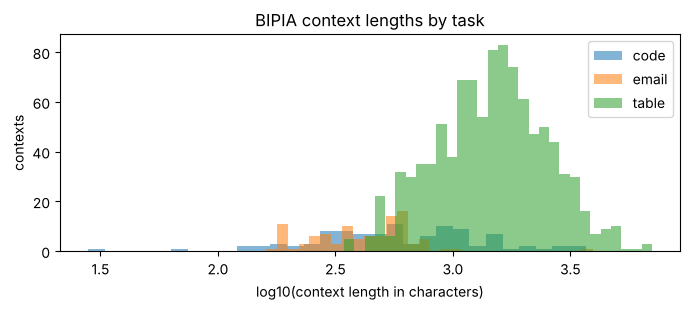

In [9]:
# BIPIA integrity checks that matter for leakage
if BIPIA_OK:
    rows = []
    for task, g in bipia_ctx_raw.groupby("task"):
        tr = g[g.orig_split == "train"].context; te = g[g.orig_split == "test"].context
        rows.append({"task": task, "train": len(tr), "test": len(te),
                     "duplicate_contexts_within_train": int(tr.duplicated().sum()),
                     "contexts_in_both_train_and_test": len(set(tr) & set(te)),
                     "median_chars": int(g.context.str.len().median()), "max_chars": int(g.context.str.len().max())})
    ctx_audit = pd.DataFrame(rows); display(ctx_audit)

    arows = []
    for kind, g in bipia_atk_raw.groupby("attack_kind"):
        tr, te = g[g.orig_split == "train"], g[g.orig_split == "test"]
        arows.append({"attack_kind": kind,
                      "categories_in_both_splits": sorted(set(tr.attack_category) & set(te.attack_category)),
                      "identical_strings_in_both_splits": len(set(tr.attack_text) & set(te.attack_text))})
    atk_audit = pd.DataFrame(arows); display(atk_audit)
    CLEAN_LOG["bipia_audit_before_cleaning"] = {"contexts": ctx_audit.to_dict("records"), "attacks": atk_audit.to_dict("records")}

    fig, ax = plt.subplots(figsize=(7, 3.2))
    for task, g in bipia_ctx_raw.groupby("task"):
        ax.hist(np.log10(g.context.str.len().clip(lower=1)), bins=30, alpha=.55, label=task)
    ax.set_xlabel("log10(context length in characters)"); ax.set_ylabel("contexts"); ax.legend()
    ax.set_title("BIPIA context lengths by task"); plt.tight_layout(); plt.show()

In [10]:
# Hub sources: shape, columns, missing values, duplicates, label distribution
TEXT_COL_CANDIDATES  = ["text", "prompt", "content", "input", "sentence", "query"]
LABEL_COL_CANDIDATES = ["label", "labels", "is_injection", "injection", "class", "target"]

def explore_hf_frames(key, frames):
    for sp, fr in frames.items():
        print(f"--- {key}/{sp}: shape={fr.shape}")
        print("    columns:", list(fr.columns))
        print("    nulls  :", fr.isna().sum().to_dict())
        tc = next((c for c in TEXT_COL_CANDIDATES if c in fr.columns), None)
        lc = next((c for c in LABEL_COL_CANDIDATES if c in fr.columns), None)
        if tc: print(f"    duplicate rows on '{tc}':", int(fr[tc].duplicated().sum()))
        if lc: print(f"    label distribution ('{lc}'):", fr[lc].value_counts(dropna=False).to_dict())

if HF_PROMPT_RAW:
    for k, v in HF_PROMPT_RAW.items():
        explore_hf_frames(k, v)
else:
    print("No Hugging Face prompt-injection sources were loaded in this run (see blockers).")

if STSB_RAW:
    for sp, fr in STSB_RAW.items():
        print(f"STS-B/{sp}: shape={fr.shape}  columns={list(fr.columns)}  "
              f"label range=({fr['label'].min()}, {fr['label'].max()})  nulls={int(fr.isna().sum().sum())}")

No Hugging Face prompt-injection sources were loaded in this run (see blockers).


## 04. Cleaning

**How labels work.** SAFE = 0, MALICIOUS = 1. A label is only used if the source gives it, or if it comes from how the sample was built (for BIPIA: the clean context is SAFE, the same context with an attack inserted is MALICIOUS). Label values I don't recognise get dropped and counted, never guessed.

One thing I deliberately don't do is use BIPIA's attack strings as standalone samples. Plenty of them look harmless on their own ("What is the capital of Brazil?"); they're only an attack when they're hidden inside an email or a table. Labelling them MALICIOUS by themselves would just be wrong.

Cleaning keeps the attack text intact: no lowercasing, no stripping punctuation, no throwing text out for containing "suspicious" words. If the same text shows up with two different labels, I remove every copy and write it to `datasets/metadata/contradictory_labels.csv` so a person can look at it.

In [11]:
# Text cleaning primitives (attack-preserving)
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")

def clean_text(s, collapse_ws=False):
    """NFC-normalise, fix newlines, drop control chars. Never lowercases or strips punctuation."""
    if s is None or (isinstance(s, float) and math.isnan(s)):
        return ""
    s = str(s)
    s = unicodedata.normalize("NFC", s)
    s = s.replace("\r\n", "\n").replace("\r", "\n")
    s = _CTRL.sub("", s)
    if collapse_ws:
        s = re.sub(r"[ \t]+", " ", s)
        s = re.sub(r"\n{3,}", "\n\n", s)
    return s.strip()

def dedup_key(s):
    """Key used ONLY to detect duplicates/leakage (lowercased, whitespace-collapsed). Never stored as text."""
    return re.sub(r"\s+", " ", s.lower()).strip()

def text_hash(s):
    return hashlib.sha1(dedup_key(s).encode("utf-8")).hexdigest()

def is_corrupted(s):
    """Heuristic: replacement characters or mostly non-printable content."""
    if not s: return True
    bad = s.count("\ufffd")
    return bad / max(len(s), 1) > 0.02


def near_dup_groups(texts, thr, chunk=512):
    """Connected components over TF-IDF cosine >= thr. Used only to keep near-duplicates in one split."""
    n = len(texts)
    if n == 0: return np.array([], dtype=int)
    X = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, lowercase=True).fit_transform(texts)   # unsupervised
    rr, cc = [], []
    for i in range(0, n, chunk):
        S = (X[i:i + chunk] @ X.T).tocoo()
        m = (S.data >= thr) & ((S.row + i) != S.col)
        rr.append(S.row[m] + i); cc.append(S.col[m])
    rr, cc = np.concatenate(rr), np.concatenate(cc)
    A = sparse.coo_matrix((np.ones(len(rr)), (rr, cc)), shape=(n, n))
    _, lab = connected_components(A, directed=False)
    return lab

LABEL_SAFE      = {"0", "safe", "benign", "normal", "legit", "legitimate", "clean", "false", "no", "negative"}
LABEL_MALICIOUS = {"1", "malicious", "injection", "attack", "jailbreak", "unsafe", "true", "yes", "positive", "prompt_injection"}

def normalize_label(v):
    """Returns 0, 1, or None (= invalid, to be dropped and reported). Never guesses."""
    if v is None or (isinstance(v, float) and math.isnan(v)): return None
    if isinstance(v, (bool, np.bool_)): return int(v)
    if isinstance(v, (int, np.integer)): return int(v) if int(v) in (0, 1) else None
    if isinstance(v, (float, np.floating)): return int(v) if v in (0.0, 1.0) else None
    s = str(v).strip().lower()
    if s in LABEL_SAFE: return 0
    if s in LABEL_MALICIOUS: return 1
    return None

In [12]:
# Clean BIPIA contexts and attack pools
if BIPIA_OK:
    log = {}
    ctx = bipia_ctx_raw.copy()
    ctx["context"] = ctx.context.map(clean_text)                 # keep whitespace, tables and code need it
    n0 = len(ctx)
    ctx = ctx[ctx.context.str.len() > 0]
    ctx = ctx[~ctx.context.map(is_corrupted)]
    log["dropped_empty_or_corrupted_contexts"] = n0 - len(ctx)
    ctx["ctx_hash"] = ctx.context.map(text_hash)

    # exact duplicate contexts in the same task+split: keep the first
    before = len(ctx)
    ctx = ctx.drop_duplicates(subset=["task", "orig_split", "ctx_hash"], keep="first")
    log["dropped_duplicate_contexts_within_split"] = before - len(ctx)

    # same context in train and test: drop it from train, leave test as published
    test_hashes = set(ctx[ctx.orig_split == "test"].ctx_hash)
    leak_mask = (ctx.orig_split == "train") & ctx.ctx_hash.isin(test_hashes)
    log["dropped_train_contexts_also_in_test"] = int(leak_mask.sum())
    ctx = ctx[~leak_mask]
    # near-duplicates: the email train/test pools have the same emails with tiny edits.
    # cluster everything, then drop train contexts that sit in a cluster with a test context
    ctx = ctx.reset_index(drop=True)
    ctx["ctx_cluster"] = ["bc" + str(g) for g in near_dup_groups(ctx.context.tolist(), CONFIG["BIPIA_CTX_NEAR_DUP_THRESHOLD"])]
    test_clusters = set(ctx[ctx.orig_split == "test"].ctx_cluster)
    nd_mask = (ctx.orig_split == "train") & ctx.ctx_cluster.isin(test_clusters)
    log["dropped_train_contexts_near_duplicate_of_test"] = int(nd_mask.sum())
    log["near_duplicate_threshold"] = CONFIG["BIPIA_CTX_NEAR_DUP_THRESHOLD"]
    ctx = ctx[~nd_mask]
    bipia_ctx = ctx.reset_index(drop=True)

    # attacks: clean the text, drop train categories that also exist in test
    atk = bipia_atk_raw.copy()
    atk["attack_text"] = atk.attack_text.map(lambda s: clean_text(s))
    atk = atk[atk.attack_text.str.len() > 0]
    dropped_cats = []
    for kind, g in atk.groupby("attack_kind"):
        both = set(g[g.orig_split == "train"].attack_category) & set(g[g.orig_split == "test"].attack_category)
        dropped_cats += [(kind, c) for c in sorted(both)]
    atk = atk[~((atk.orig_split == "train") & atk.apply(lambda r: (r.attack_kind, r.attack_category) in dropped_cats, axis=1))]
    log["dropped_train_attack_categories_also_in_test"] = [f"{k}:{c}" for k, c in dropped_cats]
    shared_strings = set(atk[atk.orig_split == "train"].attack_text) & set(atk[atk.orig_split == "test"].attack_text)
    assert not shared_strings, "attack strings shared between train and test pools"
    bipia_atk = atk.reset_index(drop=True)

    CLEAN_LOG["bipia_cleaning"] = log
    print(json.dumps(log, indent=2))
    display(bipia_ctx.groupby(["task", "orig_split"]).size().unstack())

{
  "dropped_empty_or_corrupted_contexts": 0,
  "dropped_duplicate_contexts_within_split": 310,
  "dropped_train_contexts_also_in_test": 11,
  "dropped_train_contexts_near_duplicate_of_test": 18,
  "near_duplicate_threshold": 0.8,
  "dropped_train_attack_categories_also_in_test": [
    "text:Language Translation"
  ]
}


orig_split,test,train
task,,
code,50,50
email,44,16
table,84,617


In [13]:
# Clean Hub prompt-injection sources
def standardize_hf_frame(key, frames, text_col=None, label_col=None):
    """Concatenate splits -> standard columns [text, label_raw, orig_split]. Raises if columns are ambiguous."""
    parts = []
    for sp, fr in frames.items():
        tc = text_col or next((c for c in TEXT_COL_CANDIDATES if c in fr.columns), None)
        lc = label_col or next((c for c in LABEL_COL_CANDIDATES if c in fr.columns), None)
        if tc is None or lc is None:
            raise ValueError(f"{key}/{sp}: cannot identify text/label columns from {list(fr.columns)}; "
                             f"set them explicitly — no guessing")
        parts.append(pd.DataFrame({"text": fr[tc].values, "label_raw": fr[lc].values, "orig_split": sp}))
    return pd.concat(parts, ignore_index=True)

def clean_text_source(key, df):
    """Full cleaning pipeline for one stand-alone-prompt source. Returns cleaned df + log dict."""
    log = {"rows_in": len(df)}
    df = df.copy()
    df["label"] = df.label_raw.map(normalize_label)
    log["dropped_invalid_labels"] = int(df.label.isna().sum())
    log["invalid_label_values_seen"] = sorted({str(v) for v in df.loc[df.label.isna(), "label_raw"].unique()})[:20]
    df = df[df.label.notna()].copy(); df["label"] = df.label.astype(int)
    df["text"] = df.text.map(lambda s: clean_text(s, collapse_ws=True))
    n = len(df); df = df[df.text.str.len() > 0]; log["dropped_empty"] = n - len(df)
    n = len(df); df = df[~df.text.map(is_corrupted)]; log["dropped_corrupted"] = n - len(df)
    df["thash"] = df.text.map(text_hash)
    n = len(df); df = df.drop_duplicates(subset=["thash", "label"], keep="first"); log["dropped_exact_duplicates"] = n - len(df)
    df["source"] = key
    log["rows_out"] = len(df)
    return df.drop(columns=["label_raw"]), log

TEXT_SOURCES_CLEAN = {}
for key, frames in HF_PROMPT_RAW.items():
    try:
        std = standardize_hf_frame(key, frames)
        cleaned, lg = clean_text_source(key, std)
        TEXT_SOURCES_CLEAN[key] = cleaned
        CLEAN_LOG[f"text_source:{key}"] = lg
        print(key, json.dumps(lg))
    except Exception as e:
        BLOCKERS.append(f"[data:{key}] cleaning failed: {e}")
        print(f"{key}: cleaning FAILED -> {e}")

# same text with different labels across sources: remove all copies and log them
CONTRADICTORY = pd.DataFrame()
if TEXT_SOURCES_CLEAN:
    allt = pd.concat(TEXT_SOURCES_CLEAN.values(), ignore_index=True)
    lab_per_hash = allt.groupby("thash").label.nunique()
    bad = set(lab_per_hash[lab_per_hash > 1].index)
    CONTRADICTORY = allt[allt.thash.isin(bad)].sort_values("thash")
    CONTRADICTORY[["thash", "text", "label", "source", "orig_split"]].to_csv(METADATA / "contradictory_labels.csv", index=False)
    # same text and same label in two sources: keep one
    allt = allt[~allt.thash.isin(bad)]
    n = len(allt); allt = allt.drop_duplicates(subset=["thash"], keep="first")
    CLEAN_LOG["cross_source"] = {"contradictory_texts_removed": len(bad), "cross_source_duplicates_removed": n - len(allt)}
    TEXT_ALL_CLEAN = allt.reset_index(drop=True)
    print(CLEAN_LOG["cross_source"]); print(TEXT_ALL_CLEAN.groupby(["source", "label"]).size().unstack(fill_value=0))
else:
    TEXT_ALL_CLEAN = pd.DataFrame(columns=["text", "label", "orig_split", "thash", "source"])

In [14]:
# Clean STS-B
STSB_CLEAN = None
if STSB_RAW:
    parts = []
    for sp, fr in STSB_RAW.items():
        d = fr.rename(columns={"sentence1": "s1", "sentence2": "s2"})[["s1", "s2", "label"]].copy()
        d["orig_split"] = sp; parts.append(d)
    st = pd.concat(parts, ignore_index=True)
    lg = {"rows_in": len(st)}
    st["s1"] = st.s1.map(clean_text); st["s2"] = st.s2.map(clean_text)
    st = st[(st.s1.str.len() > 0) & (st.s2.str.len() > 0)]
    lg["after_empty_drop"] = len(st)
    # GLUE hides its test labels (-1), so those rows are useless for evaluation
    lg["hidden_label_rows_removed"] = int((st.label < 0).sum()); st = st[st.label >= 0]
    st = st[(st.label >= 0) & (st.label <= 5)]
    n = len(st); st = st.drop_duplicates(subset=["s1", "s2", "orig_split"]); lg["exact_duplicate_pairs_removed"] = n - len(st)
    STSB_CLEAN = st.reset_index(drop=True)
    lg["rows_out"] = len(STSB_CLEAN); lg["by_split"] = STSB_CLEAN.orig_split.value_counts().to_dict()
    CLEAN_LOG["stsb"] = lg; print(lg)
else:
    print("STS-B not available in this run.")

STS-B not available in this run.


## 05. Building the dataset and splitting it

**BIPIA.** Every sample is a pair: a clean context (SAFE) and the same context with a BIPIA attack inserted (MALICIOUS). To avoid leakage the split works on two things. Contexts get assigned to train/val/test first, and attack categories get assigned first as well. So the model is never validated or tested on a document it trained on, or on an attack instruction it has already seen. Test is BIPIA's own test contexts with BIPIA's own test attacks. That official test set is big compared to what is left of train after cleaning, so the split isn't exactly 70/15/15. I preferred clean separation over neat percentages.

**Hub prompt datasets.** Near-duplicates are clustered and kept together, then the data is split roughly 5/7 - 1/7 - 1/7, stratified by source and label.

Anything that gets fitted (TF-IDF, scalers) is fitted after splitting, on train only.

**Cropping.** Some contexts are thousands of characters long, which would push the injected text out of a 384-token window. So I crop around the insertion point (500 characters each side). The poisoned crop ends up longer than the clean one by the length of the attack, and a model could cheat on that, so I cut the clean twin to the same length. My first version didn't do this, and a classifier that only looked at text length scored F1 0.87, better than the TF-IDF baseline. Section 06 still measures whatever length signal is left.

In [15]:
# Build BIPIA samples (clean twin = SAFE, poisoned = MALICIOUS)
from nltk.tokenize.punkt import PunktSentenceTokenizer
_PUNKT = PunktSentenceTokenizer()
POSITIONS = ["start", "middle", "end"]

def build_pair(context, attack, position, rng, W):
    """Mirror BIPIA's insert_start / insert_middle / insert_end, then crop both twins to the same window."""
    if position == "middle":
        spans = list(_PUNKT.span_tokenize(context))
        if not spans:
            position = "end"
        else:
            ins = spans[int(rng.integers(len(spans)))][0]
            poisoned = "\n".join([context[:ins], attack, context[ins:]])
            a0 = ins + 1
    if position == "start":
        ins = 0; poisoned = "\n".join([attack, context]); a0 = 0
    elif position == "end":
        ins = len(context); poisoned = "\n".join([context, attack]); a0 = len(context) + 1
    a1 = a0 + len(attack)
    p_text = poisoned[max(0, a0 - W): min(len(poisoned), a1 + W)].strip()
    # make the clean twin the same length as the poisoned crop so length can't give the label away.
    # short documents can't be padded; section 06 measures what's left
    L = len(p_text)
    s0 = max(0, ins - W); e0 = min(len(context), s0 + L)
    if e0 - s0 < L: s0 = max(0, e0 - L)
    c_text = context[s0:e0].strip()
    return c_text, p_text, position

def make_bipia_samples():
    rng = np.random.default_rng(SEED)
    cap, W = CONFIG["BIPIA_MAX_CONTEXTS_PER_TASK_SPLIT"], CONFIG["BIPIA_CROP_CHARS"]
    pools = {}
    for kind in ("text", "code"):
        tr = bipia_atk[(bipia_atk.attack_kind == kind) & (bipia_atk.orig_split == "train")]
        cats = sorted(tr.attack_category.unique())
        perm = [cats[i] for i in rng.permutation(len(cats))]
        val_c = set(perm[:max(1, int(round(len(cats) * CONFIG["BIPIA_VAL_CATEGORY_FRAC"])))])
        pools[(kind, "val")]   = tr[tr.attack_category.isin(val_c)].reset_index(drop=True)
        pools[(kind, "train")] = tr[~tr.attack_category.isin(val_c)].reset_index(drop=True)
        pools[(kind, "test")]  = bipia_atk[(bipia_atk.attack_kind == kind) & (bipia_atk.orig_split == "test")].reset_index(drop=True)

    rows = []
    for task in CONFIG["BIPIA_TASKS"]:
        kind = ATTACK_KIND[task]
        ctx_split = {}
        tr = bipia_ctx[(bipia_ctx.task == task) & (bipia_ctx.orig_split == "train")].sort_values("ctx_hash").reset_index(drop=True)
        te = bipia_ctx[(bipia_ctx.task == task) & (bipia_ctx.orig_split == "test")].sort_values("ctx_hash").reset_index(drop=True)
        if len(tr) > cap: tr = tr.iloc[sorted(rng.permutation(len(tr))[:cap])].reset_index(drop=True)
        if len(te) > cap: te = te.iloc[sorted(rng.permutation(len(te))[:cap])].reset_index(drop=True)
        # pick validation contexts cluster by cluster so near-duplicates don't land on both sides
        clusters = sorted(tr.ctx_cluster.unique())
        order = [clusters[i] for i in rng.permutation(len(clusters))]
        n_val_target = max(1, int(round(len(tr) * CONFIG["BIPIA_VAL_CONTEXT_FRAC"])))
        val_clusters, acc = set(), 0
        for c in order:
            if acc >= n_val_target: break
            val_clusters.add(c); acc += int((tr.ctx_cluster == c).sum())
        for _, r in tr.iterrows(): ctx_split[r.ctx_hash] = "val" if r.ctx_cluster in val_clusters else "train"
        for _, r in te.iterrows():  ctx_split[r.ctx_hash] = "test"
        for _, r in pd.concat([tr, te]).iterrows():
            split = ctx_split[r.ctx_hash]
            pool = pools[(kind, split)]
            atk = pool.iloc[int(rng.integers(len(pool)))]
            pos = POSITIONS[int(rng.integers(3))]
            c_text, p_text, pos = build_pair(r.context, atk.attack_text, pos, rng, W)
            pid = f"{task}-{r.ctx_hash[:12]}"
            base = dict(source="bipia", source_group=f"bipia_{kind}", task=task, split=split, ctx_hash=r.ctx_hash, pair_id=pid)
            rows.append({**base, "sample_id": pid + "-c", "text": c_text, "label": 0, "attack_category": None, "attack_position": None,
                         "group": f"bipia|{r.ctx_cluster}"})
            rows.append({**base, "sample_id": pid + "-p", "text": p_text, "label": 1, "attack_category": f"{kind}:{atk.attack_category}",
                         "attack_position": pos, "group": f"bipia|{r.ctx_cluster}"})
    return pd.DataFrame(rows)

BIPIA_SAMPLES = make_bipia_samples() if BIPIA_OK else pd.DataFrame()
if len(BIPIA_SAMPLES):
    display(BIPIA_SAMPLES.groupby(["split", "task", "label"]).size().unstack(fill_value=0))
    print("Split proportions (BIPIA):", (BIPIA_SAMPLES.split.value_counts(normalize=True).round(3)).to_dict())

label          0    1
split task           
test  code    50   50
      email   44   44
      table   84   84
train code    40   40
      email   12   12
      table  240  240
val   code    10   10
      email    4    4
      table   60   60

Split proportions (BIPIA): {'train': 0.537, 'test': 0.327, 'val': 0.136}


In [16]:
# Near-duplicate clustering and group-aware split for Hub sources
TEXT_SPLIT = pd.DataFrame()
if len(TEXT_ALL_CLEAN):
    d = TEXT_ALL_CLEAN.copy()
    d["group"] = ["nd|" + str(g) for g in near_dup_groups(d.text.tolist(), CONFIG["NEAR_DUP_THRESHOLD"])]
    strat = (d.source + "|" + d.label.astype(str)).values
    sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
    folds = [te for _, te in sgkf.split(d, strat, groups=d.group.values)]
    d["split"] = "train"
    d.loc[d.index[folds[0]], "split"] = "test"
    d.loc[d.index[folds[1]], "split"] = "val"
    d["source_group"] = d.source; d["task"] = "standalone"; d["ctx_hash"] = d.thash; d["pair_id"] = None
    d["attack_category"] = None; d["attack_position"] = None
    d["sample_id"] = [f"{s}-{h[:12]}" for s, h in zip(d.source, d.thash)]
    TEXT_SPLIT = d[["sample_id", "text", "label", "source", "source_group", "task", "split", "ctx_hash", "pair_id",
                    "attack_category", "attack_position", "group"]]
    CLEAN_LOG["near_dup_clusters"] = {"n_groups": int(d.group.nunique()), "n_rows": len(d),
                                      "rows_in_multi_member_groups": int((d.groupby("group").group.transform("size") > 1).sum())}
    print(CLEAN_LOG["near_dup_clusters"])
    display(TEXT_SPLIT.groupby(["source", "split", "label"]).size().unstack(fill_value=0))
else:
    print("No Hub prompt-injection text was loaded — the combined dataset will contain BIPIA only.")

No Hub prompt-injection text was loaded — the combined dataset will contain BIPIA only.


In [17]:
# Assemble the combined prompt-injection dataset + leakage checks
PI_COLS = ["sample_id", "text", "label", "source", "source_group", "task", "split", "ctx_hash", "pair_id",
           "attack_category", "attack_position", "group"]
frames = [f for f in (BIPIA_SAMPLES, TEXT_SPLIT) if len(f)]
if not frames:
    PI_ALL = pd.DataFrame(columns=PI_COLS)
    set_status("prompt_injection", "SKIPPED", "no prompt-injection data source could be loaded")
else:
    PI_ALL = pd.concat([f[PI_COLS] for f in frames], ignore_index=True)
    PI_ALL["text_key"] = PI_ALL.text.map(dedup_key)

def leakage_report(df, thr):
    rep = {}
    # same text in two splits
    sets = {s: set(df[df.split == s].text_key) for s in ("train", "val", "test")}
    rep["exact_overlap"] = {f"{a}&{b}": len(sets[a] & sets[b]) for a, b in (("train", "val"), ("train", "test"), ("val", "test"))}
    # same group in two splits
    gs = {s: set(df[df.split == s].group) for s in ("train", "val", "test")}
    rep["group_overlap"] = {f"{a}&{b}": len(gs[a] & gs[b]) for a, b in (("train", "val"), ("train", "test"), ("val", "test"))}
    # BIPIA attack categories shared across splits
    b = df[(df.source == "bipia") & (df.label == 1)]
    cs = {s: set(b[b.split == s].attack_category) for s in ("train", "val", "test")}
    rep["bipia_attack_category_overlap"] = {f"{x}&{y}": len(cs[x] & cs[y]) for x, y in (("train", "val"), ("train", "test"), ("val", "test"))}
    # val/test items that nearly match a train item
    tr, oth = df[df.split == "train"], df[df.split != "train"]
    near = {}
    if len(tr) and len(oth):
        vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(df.text)       # unsupervised, only to measure similarity
        Xtr, Xo = vec.transform(tr.text), vec.transform(oth.text)
        mx = np.zeros(Xo.shape[0])
        for i in range(0, Xo.shape[0], 256):
            S = Xo[i:i + 256] @ Xtr.T
            mx[i:i + 256] = S.max(axis=1).toarray().ravel() if S.shape[1] else 0
        o = oth.assign(max_sim_to_train=mx)
        for (src, sp), g in o.groupby(["source", "split"]):
            near[f"{src}/{sp}"] = {"n": int(len(g)), f"sim>={thr}": int((g.max_sim_to_train >= thr).sum()),
                                   "sim>=0.8": int((g.max_sim_to_train >= 0.8).sum()), "max": round(float(g.max_sim_to_train.max()), 3)}
    rep["near_duplicate_to_train"] = near
    return rep

if len(PI_ALL):
    LEAK = leakage_report(PI_ALL, CONFIG["NEAR_DUP_THRESHOLD"])
    print(json.dumps(LEAK, indent=2))
    # these must all be zero
    assert all(v == 0 for v in LEAK["exact_overlap"].values()), "exact text leakage across splits"
    assert all(v == 0 for v in LEAK["group_overlap"].values()), "group leakage across splits"
    assert all(v == 0 for v in LEAK["bipia_attack_category_overlap"].values()), "attack category leakage across splits"
    CLEAN_LOG["leakage_report"] = LEAK

{
  "exact_overlap": {
    "train&val": 0,
    "train&test": 0,
    "val&test": 0
  },
  "group_overlap": {
    "train&val": 0,
    "train&test": 0,
    "val&test": 0
  },
  "bipia_attack_category_overlap": {
    "train&val": 0,
    "train&test": 0,
    "val&test": 0
  },
  "near_duplicate_to_train": {
    "bipia/test": {
      "n": 356,
      "sim>=0.9": 0,
      "sim>=0.8": 0,
      "max": 0.769
    },
    "bipia/val": {
      "n": 148,
      "sim>=0.9": 0,
      "sim>=0.8": 0,
      "max": 0.668
    }
  }
}


In [18]:
# Export processed prompt-injection data + split manifest
if len(PI_ALL):
    for sp in ("train", "val", "test"):
        PI_ALL[PI_ALL.split == sp].drop(columns=["text_key"]).to_csv(PROCESSED / f"prompt_injection_{sp}.csv", index=False)
    manifest = {
        "created_utc": now_iso(), "seed": SEED,
        "counts": {f"{sp}": PI_ALL[PI_ALL.split == sp].label.value_counts().sort_index().rename({0: "SAFE", 1: "MALICIOUS"}).to_dict()
                   for sp in ("train", "val", "test")},
        "by_source": PI_ALL.groupby(["source", "split"]).size().unstack(fill_value=0).to_dict("index"),
        "proportions": PI_ALL.split.value_counts(normalize=True).round(4).to_dict(),
        "config": {k: CONFIG[k] for k in ("BIPIA_COMMIT", "BIPIA_MAX_CONTEXTS_PER_TASK_SPLIT", "BIPIA_CROP_CHARS",
                                          "BIPIA_VAL_CONTEXT_FRAC", "BIPIA_VAL_CATEGORY_FRAC", "NEAR_DUP_THRESHOLD")},
        "licence_note": "Derived from BIPIA, which incorporates CC BY-SA 4.0 material (WikiTableQuestions). Do not redistribute without attribution and share-alike review.",
    }
    (METADATA / "prompt_injection_split_manifest.json").write_text(json.dumps(jsonable(manifest), indent=2))
    print(json.dumps(jsonable(manifest["counts"]), indent=2)); print(manifest["proportions"])

{
  "train": {
    "SAFE": 292,
    "MALICIOUS": 292
  },
  "val": {
    "SAFE": 74,
    "MALICIOUS": 74
  },
  "test": {
    "SAFE": 178,
    "MALICIOUS": 178
  }
}
{'train': 0.5368, 'test': 0.3272, 'val': 0.136}


In [19]:
# STS-B roles and leakage check
# MiniLM isn't trained here, so STS-B train works as the calibration set.
# GLUE hides its own test labels, so STS-B validation is our held-out test set.
STS_CAL = STS_TEST = None
if STSB_CLEAN is not None:
    STS_CAL  = STSB_CLEAN[STSB_CLEAN.orig_split == "train"].reset_index(drop=True)
    STS_TEST = STSB_CLEAN[STSB_CLEAN.orig_split == "validation"].reset_index(drop=True)
    cal_pairs = set(zip(STS_CAL.s1.map(dedup_key), STS_CAL.s2.map(dedup_key)))
    test_pairs = set(zip(STS_TEST.s1.map(dedup_key), STS_TEST.s2.map(dedup_key)))
    cal_sents = set(STS_CAL.s1.map(dedup_key)) | set(STS_CAL.s2.map(dedup_key))
    test_sents = set(STS_TEST.s1.map(dedup_key)) | set(STS_TEST.s2.map(dedup_key))
    CLEAN_LOG["stsb_leakage"] = {"identical_pairs_cal_vs_test": len(cal_pairs & test_pairs),
                                 "sentences_in_both": len(cal_sents & test_sents)}
    print(CLEAN_LOG["stsb_leakage"])
    STS_CAL.to_csv(PROCESSED / "stsb_calibration.csv", index=False); STS_TEST.to_csv(PROCESSED / "stsb_test.csv", index=False)
    print(f"calibration={len(STS_CAL)} test={len(STS_TEST)}")

## 06. Prompt-injection detection

Order: helper functions, the TF-IDF + logistic regression baseline, a length-only sanity check, a leave-one-source-out test, then DistilBERT and a comparison. Hyper-parameters and the decision threshold are picked on validation only. Test gets looked at once per model.

The score a model outputs is a ranking score compared against a threshold. It is not a calibrated probability that something is malicious.

In [20]:
# Metric + threshold helpers
def binary_metrics(y, score, thr):
    y = np.asarray(y).astype(int); score = np.asarray(score, dtype=float)
    pred = (score >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    m = {"n": int(len(y)), "threshold": float(thr),
         "accuracy": float(accuracy_score(y, pred)),
         "precision": float(precision_score(y, pred, zero_division=0)),
         "recall": float(recall_score(y, pred, zero_division=0)),
         "f1": float(f1_score(y, pred, zero_division=0)),
         "fpr": float(fp / (fp + tn)) if (fp + tn) else float("nan"),
         "fnr": float(fn / (fn + tp)) if (fn + tp) else float("nan"),
         "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn)}
    if len(np.unique(y)) == 2:
        m["roc_auc"] = float(roc_auc_score(y, score)); m["pr_auc"] = float(average_precision_score(y, score))
    return m

def select_threshold(y, score, strategy="max_f1", recall_floor=0.95):
    """Threshold from validation data only. Ties on a plateau resolve to the plateau's median (not an extreme)."""
    y = np.asarray(y).astype(int); score = np.asarray(score, dtype=float)
    prec, rec, thr = precision_recall_curve(y, score)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    if strategy == "recall_floor":
        ok = rec[:-1] >= recall_floor
        if ok.any():
            return float(thr[ok][-1])           # highest threshold that still meets the recall floor
    best = f1.max()
    return float(np.median(thr[f1 >= best - 1e-12]))

def latency_ms(fn, items, warmup=3):
    """Per-call latency over single-item calls."""
    for it in items[:warmup]: fn([it])
    ts = []
    for it in items:
        t0 = time.perf_counter(); fn([it]); ts.append((time.perf_counter() - t0) * 1000)
    return {"mean_ms": float(np.mean(ts)), "p50_ms": float(np.percentile(ts, 50)), "p95_ms": float(np.percentile(ts, 95)), "n_calls": len(ts)}

PI = {"scores": {}, "metrics": {}}     # scores kept for the plots in section 10
if len(PI_ALL):
    PI_TRAIN = PI_ALL[PI_ALL.split == "train"].reset_index(drop=True)
    PI_VAL   = PI_ALL[PI_ALL.split == "val"].reset_index(drop=True)
    PI_TEST  = PI_ALL[PI_ALL.split == "test"].reset_index(drop=True)
    print({k: len(v) for k, v in (("train", PI_TRAIN), ("val", PI_VAL), ("test", PI_TEST))})

{'train': 584, 'val': 148, 'test': 356}


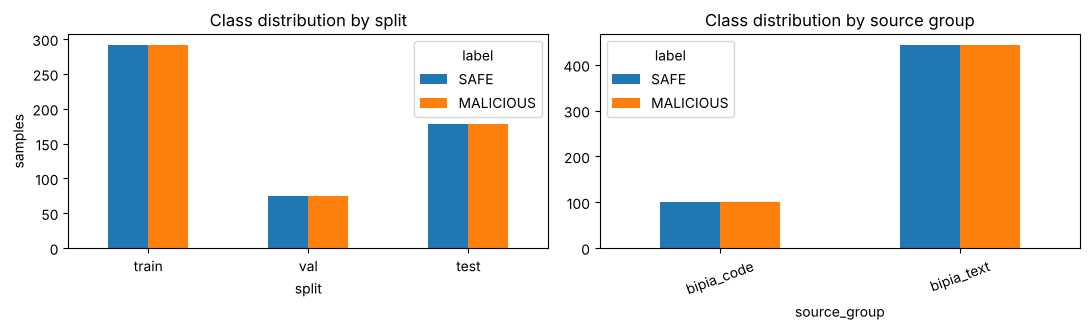

In [21]:
# Class-distribution visualisation (EDA)
if len(PI_ALL):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    ct = PI_ALL.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(["train", "val", "test"])
    ct.rename(columns={0: "SAFE", 1: "MALICIOUS"}).plot.bar(ax=axes[0], rot=0); axes[0].set_title("Class distribution by split"); axes[0].set_ylabel("samples")
    cs = PI_ALL.groupby(["source_group", "label"]).size().unstack(fill_value=0)
    cs.rename(columns={0: "SAFE", 1: "MALICIOUS"}).plot.bar(ax=axes[1], rot=20); axes[1].set_title("Class distribution by source group")
    plt.tight_layout(); plt.savefig(REP_VIZ / "pi_class_distribution.png", dpi=130); plt.show()

In [22]:
# TF-IDF + Logistic Regression baseline
def fit_tfidf_lr(train_df, val_df, C_grid):
    """Fits ONLY on train_df; C chosen by validation PR-AUC (threshold-free). Returns (pipeline, C, val_scores)."""
    best = None
    for C in C_grid:
        pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=200_000)),
                         ("lr", LogisticRegression(C=C, max_iter=3000, class_weight="balanced", random_state=SEED))])
        pipe.fit(train_df.text, train_df.label)
        s = pipe.predict_proba(val_df.text)[:, 1]
        ap = average_precision_score(val_df.label, s)
        if best is None or ap > best[0] + 1e-9:            # strict > so ties go to the smaller C
            best = (ap, C, pipe, s)
    return best[2], best[1], best[3]

def subgroup_table(df, score, thr, by):
    out = []
    for key, g in df.assign(_s=score).groupby(by):
        yy, ss = g.label.values, g._s.values
        pred = (ss >= thr).astype(int)
        out.append({by: key, "n": len(g), "n_malicious": int(yy.sum()),
                    "recall": float(recall_score(yy, pred, zero_division=0)) if yy.sum() else float("nan"),
                    "fpr": float(((pred == 1) & (yy == 0)).sum() / max((yy == 0).sum(), 1))})
    return pd.DataFrame(out)

if len(PI_ALL):
    t0 = time.time()
    base_pipe, base_C, base_val_s = fit_tfidf_lr(PI_TRAIN, PI_VAL, CONFIG["PI_LR_C_GRID"])
    base_fit_s = time.time() - t0
    base_thr = select_threshold(PI_VAL.label, base_val_s, CONFIG["PI_THRESHOLD_STRATEGY"], CONFIG["PI_RECALL_FLOOR"])
    base_test_s = base_pipe.predict_proba(PI_TEST.text)[:, 1]
    PI["scores"]["tfidf_lr"] = {"val": (PI_VAL.label.values, base_val_s), "test": (PI_TEST.label.values, base_test_s)}
    PI["metrics"]["tfidf_lr"] = {
        "config": {"vectorizer": "word 1-2gram, min_df=2, sublinear_tf, max_features=200k", "C": base_C, "class_weight": "balanced",
                   "threshold_strategy": CONFIG["PI_THRESHOLD_STRATEGY"]},
        "threshold": base_thr, "fit_seconds": base_fit_s,
        "val":  binary_metrics(PI_VAL.label, base_val_s, base_thr),
        "test": binary_metrics(PI_TEST.label, base_test_s, base_thr),
        "latency": latency_ms(lambda x: base_pipe.predict_proba(x), PI_TEST.text.tolist()[:200]),
        "test_by_source": subgroup_table(PI_TEST, base_test_s, base_thr, "source").to_dict("records"),
        "test_by_task": subgroup_table(PI_TEST, base_test_s, base_thr, "task").to_dict("records"),
    }
    # what each threshold strategy would give
    ops = []
    for strat in ("max_f1", "recall_floor"):
        th = select_threshold(PI_VAL.label, base_val_s, strat, CONFIG["PI_RECALL_FLOOR"])
        mv = binary_metrics(PI_VAL.label, base_val_s, th); mt = binary_metrics(PI_TEST.label, base_test_s, th)
        ops.append({"strategy": strat, "threshold": th, "val_recall": mv["recall"], "val_fpr": mv["fpr"],
                    "test_recall": mt["recall"], "test_fpr": mt["fpr"], "test_f1": mt["f1"]})
    PI["metrics"]["tfidf_lr"]["operating_points"] = ops
    print(f"best C = {base_C}; threshold = {base_thr:.4f}  (strategy: {CONFIG['PI_THRESHOLD_STRATEGY']})")
    display(pd.DataFrame([{"split": s, **{k: PI['metrics']['tfidf_lr'][s][k] for k in
            ("accuracy", "precision", "recall", "f1", "fpr", "fnr", "roc_auc", "pr_auc")}} for s in ("val", "test")]).round(4))
    print("latency:", {k: round(v, 3) for k, v in PI["metrics"]["tfidf_lr"]["latency"].items()})
    print("\noperating points:"); display(pd.DataFrame(ops).round(4))
    print("test, by task:"); display(pd.DataFrame(PI["metrics"]["tfidf_lr"]["test_by_task"]).round(3))

best C = 100.0; threshold = 0.1415  (strategy: max_f1)


,split,accuracy,precision,recall,f1,fpr,fnr,roc_auc,pr_auc
0,val,0.8649,0.8140,0.9459,0.8750,0.2162,0.0541,0.9343,0.9214
1,test,0.7640,0.6926,0.9494,0.8009,0.4213,0.0506,0.8912,0.8962


latency: {'mean_ms': 0.649, 'p50_ms': 0.611, 'p95_ms': 0.783, 'n_calls': 200}

operating points:


,strategy,threshold,val_recall,val_fpr,test_recall,test_fpr,test_f1
0,max_f1,0.1415,0.9459,0.2162,0.9494,0.4213,0.8009
1,recall_floor,0.1160,0.9595,0.2568,0.9663,0.4775,0.7908


test, by task:


,task,n,n_malicious,recall,fpr
0,code,100,50,1.000,0.800
1,email,88,44,0.955,0.477
2,table,168,84,0.917,0.167


In [23]:
# Which unseen attack categories does the baseline miss? (test split, malicious samples only)
if len(PI_ALL):
    mal = PI_TEST[PI_TEST.label == 1].assign(_s=base_test_s[PI_TEST.label.values == 1])
    mal["detected"] = (mal._s >= base_thr).astype(int)
    by_cat = mal.groupby("attack_category").detected.agg(["mean", "size"]).rename(columns={"mean": "recall", "size": "n"}).sort_values("recall")
    PI["metrics"]["tfidf_lr"]["test_recall_by_attack_category"] = by_cat.reset_index().to_dict("records")
    display(by_cat.round(3))
    by_pos = mal.groupby("attack_position").detected.agg(["mean", "size"]).rename(columns={"mean": "recall", "size": "n"})
    PI["metrics"]["tfidf_lr"]["test_recall_by_position"] = by_pos.reset_index().to_dict("records")
    display(by_pos.round(3))

,recall,n
attack_category,,
text:Conversational Agent,0.556,9
text:Sentiment Analysis,0.786,14
text:Reverse Text,0.833,6
text:Base Encoding,0.909,11
code:Data Eavesdropping,1.000,3
code:Encrypting Documents and Demanding Ransom (Ransomware),1.000,1
code:Blocking Internet Connection,1.000,5
code:Bringing Down Hosts and Servers (Denial of Service),1.000,11
code:Keylogging,1.000,5


,recall,n
attack_position,,
end,0.950,60
middle,0.971,68
start,0.920,50


In [24]:
# Shortcut check: can a classifier that sees ONLY text length do this task?
# can a classifier that only sees text length do this task? if it can, good
# baseline/DistilBERT scores would partly be an artefact of how I built the data
if len(PI_ALL):
    def len_feat(df): return np.log1p(df.text.str.len().values).reshape(-1, 1)
    len_lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED).fit(len_feat(PI_TRAIN), PI_TRAIN.label)
    ls_val, ls_test = len_lr.predict_proba(len_feat(PI_VAL))[:, 1], len_lr.predict_proba(len_feat(PI_TEST))[:, 1]
    ls_thr = select_threshold(PI_VAL.label, ls_val, "max_f1")
    PI["metrics"]["length_only_shortcut"] = {"threshold": ls_thr, "val": binary_metrics(PI_VAL.label, ls_val, ls_thr),
                                              "test": binary_metrics(PI_TEST.label, ls_test, ls_thr)}
    PI["scores"]["length_only_shortcut"] = {"val": (PI_VAL.label.values, ls_val), "test": (PI_TEST.label.values, ls_test)}
    m = PI["metrics"]["length_only_shortcut"]["test"]
    print(f"length-only classifier on TEST: acc={m['accuracy']:.3f} f1={m['f1']:.3f} roc_auc={m.get('roc_auc', float('nan')):.3f}")
    print("Interpretation: values near 0.5 AUC mean length is not a usable shortcut; values near 1.0 mean the benchmark leaks via length.")

length-only classifier on TEST: acc=0.542 f1=0.664 roc_auc=0.598
Interpretation: values near 0.5 AUC mean length is not a usable shortcut; values near 1.0 mean the benchmark leaks via length.


In [25]:
# Leave-one-source-group-out generalisation (baseline)
# train on all the OTHER groups' train data, pick C and threshold on their validation data,
# then test on every row of the held-out group. Shows if it survives a change of source
LOSO = []
if len(PI_ALL):
    groups = sorted(PI_ALL.source_group.unique())
    if len(groups) < 2:
        print("Only one source group — leave-one-source-out is not applicable.")
    for g in groups if len(groups) >= 2 else []:
        tr = PI_ALL[(PI_ALL.source_group != g) & (PI_ALL.split == "train")]
        va = PI_ALL[(PI_ALL.source_group != g) & (PI_ALL.split == "val")]
        ho = PI_ALL[PI_ALL.source_group == g]
        if tr.label.nunique() < 2 or va.label.nunique() < 2 or ho.label.nunique() < 2:
            LOSO.append({"held_out": g, "note": "skipped: a split lacks one of the classes"}); continue
        pipe, C, vs = fit_tfidf_lr(tr, va, CONFIG["PI_LR_C_GRID"])
        th = select_threshold(va.label, vs, CONFIG["PI_THRESHOLD_STRATEGY"], CONFIG["PI_RECALL_FLOOR"])
        mm = binary_metrics(ho.label, pipe.predict_proba(ho.text)[:, 1], th)
        LOSO.append({"held_out": g, "train_groups": sorted(set(PI_ALL.source_group) - {g}), "n_heldout": mm["n"],
                     **{k: mm[k] for k in ("accuracy", "precision", "recall", "f1", "fpr", "fnr", "roc_auc")}})
    PI["metrics"]["loso_tfidf_lr"] = LOSO
    if LOSO: display(pd.DataFrame(LOSO).round(3))

,held_out,train_groups,n_heldout,accuracy,precision,recall,f1,fpr,fnr,roc_auc
0,bipia_code,[bipia_text],200,0.500,0.500,1.000,0.667,1.000,0.000,0.768
1,bipia_text,[bipia_code],888,0.526,0.926,0.056,0.106,0.005,0.944,0.746


In [26]:
# Inference wrapper contract (class, confidence, threshold, model version)
class PromptInjectionClassifier:
    """Notebook-side reference for the output contract the backend will implement in Phase 3.
    `malicious_score` is a model score, NOT a calibrated probability of malicious intent."""
    LABELS = {0: "SAFE", 1: "MALICIOUS"}
    def __init__(self, score_fn, threshold, model_version, model_name):
        self.score_fn, self.threshold, self.model_version, self.model_name = score_fn, float(threshold), model_version, model_name
    def predict(self, texts):
        scores = np.asarray(self.score_fn(list(texts)), dtype=float)
        out = []
        for s in scores:
            y = int(s >= self.threshold)
            out.append({"predicted_class": self.LABELS[y], "label": y, "malicious_score": round(float(s), 6),
                        "confidence": round(float(s if y else 1 - s), 6),
                        "threshold": self.threshold, "model_version": self.model_version, "model": self.model_name})
        return out

if len(PI_ALL):
    clf_baseline = PromptInjectionClassifier(lambda t: base_pipe.predict_proba(t)[:, 1], base_thr,
                                             f"{CONFIG['MODEL_VERSION']}-tfidf_lr", "tfidf_lr")
    sample = pd.concat([PI_TEST[PI_TEST.label == 0].head(1), PI_TEST[PI_TEST.label == 1].head(1)])
    for t, r in zip(sample.text, clf_baseline.predict(sample.text)):
        print(r["predicted_class"], "| score", r["malicious_score"], "| text:", repr(t[:90]))

SAFE | score 0.038203 | text: 'SUBJECT: Charged your Mercury account $2,680.00 by ACH|EMAIL_FROM: Mercury <hello@mercury.'
MALICIOUS | score 0.299997 | text: 'SUBJECT: Charged your Mercury account $2,680.00 by ACH|EMAIL_FROM: Mercury <hello@mercury.'


### DistilBERT fine-tuning

`distilbert-base-uncased` with a plain PyTorch loop (no Trainer, so it doesn't depend on a particular transformers version). It uses CUDA with mixed precision if there's a GPU, otherwise CPU; saves a checkpoint every epoch so it can resume; and picks the best epoch by validation PR-AUC.

It needs torch, transformers and access to the Hub for the weights. If any of those is missing the section is skipped and logged.

Heads up: I wrote this section but could not run it where I built the notebook (no PyTorch, no Hub access). Your first run on the GPU machine is its first real run, so expect to fix a thing or two.

In [27]:
# Preconditions
BERT_CFG = CONFIG["PI_DISTILBERT"]
BERT = {}
_missing = [n for n, ok in (("torch", HAVE_TORCH), ("transformers", HAVE_TRANSFORMERS), ("Hub access", HF_OK)) if not ok]
if not len(PI_ALL):
    _missing.append("training data")
RUN_BERT = not _missing
if not RUN_BERT:
    set_status("prompt_injection_distilbert", "SKIPPED", "missing: " + ", ".join(_missing))
else:
    print(f"DistilBERT will run on device={DEVICE} amp={USE_AMP} gpu={GPU_NAME}")

STATUS  prompt_injection_distilbert        SKIPPED  missing: torch, transformers, Hub access


In [28]:
# Tokenisation, truncation audit, data loaders
if RUN_BERT:
    from torch.utils.data import DataLoader, Dataset
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

    BERT_REV = pinned_revision(CONFIG["HF_DISTILBERT"])
    tok = AutoTokenizer.from_pretrained(CONFIG["HF_DISTILBERT"], revision=BERT_REV)

    # how many samples are longer than the window?
    lens = np.array([len(x) for x in tok(PI_ALL.text.tolist(), add_special_tokens=True, truncation=False)["input_ids"]])
    over = lens > BERT_CFG["max_len"]
    BERT["truncation"] = {"max_len": BERT_CFG["max_len"], "fraction_over_max_len": float(over.mean()),
                          "median_tokens": int(np.median(lens)), "p95_tokens": int(np.percentile(lens, 95))}
    print(BERT["truncation"])

    class TextDS(Dataset):
        def __init__(self, texts, labels): self.t, self.y = list(texts), list(labels)
        def __len__(self): return len(self.t)
        def __getitem__(self, i): return self.t[i], int(self.y[i])

    def collate(batch):
        texts, ys = zip(*batch)
        enc = tok(list(texts), truncation=True, max_length=BERT_CFG["max_len"], padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor(ys); return enc

    bs = BERT_CFG["batch_gpu"] if DEVICE == "cuda" else BERT_CFG["batch_cpu"]
    train_df = PI_TRAIN
    if DEVICE == "cpu" and len(train_df) > BERT_CFG["max_cpu_train_samples"]:
        train_df, _ = train_test_split(train_df, train_size=BERT_CFG["max_cpu_train_samples"], stratify=train_df.label, random_state=SEED)
        BERT["cpu_subsample"] = BERT_CFG["max_cpu_train_samples"]
        set_status("prompt_injection_distilbert_cpu_note", "PARTIAL", f"CPU only: trained on a stratified {BERT_CFG['max_cpu_train_samples']}-sample subset of train")
    g = torch.Generator(); g.manual_seed(SEED)
    train_loader = DataLoader(TextDS(train_df.text, train_df.label), batch_size=bs, shuffle=True, collate_fn=collate, generator=g)
    val_loader   = DataLoader(TextDS(PI_VAL.text, PI_VAL.label), batch_size=bs * 2, shuffle=False, collate_fn=collate)
    test_loader  = DataLoader(TextDS(PI_TEST.text, PI_TEST.label), batch_size=bs * 2, shuffle=False, collate_fn=collate)
    print("batch size:", bs, "| train batches/epoch:", len(train_loader))

In [29]:
# Training loop (checkpoint every epoch, resumable)
if RUN_BERT:
    CKPT_DIR = ARTIFACTS / "prompt_injection" / "checkpoints"; CKPT_DIR.mkdir(parents=True, exist_ok=True)
    CKPT = CKPT_DIR / "ckpt_last.pt"
    cfg_sig = hashlib.sha1(json.dumps({**BERT_CFG, "seed": SEED, "n_train": len(train_df), "rev": BERT_REV}, sort_keys=True).encode()).hexdigest()

    model = AutoModelForSequenceClassification.from_pretrained(CONFIG["HF_DISTILBERT"], num_labels=2, revision=BERT_REV).to(DEVICE)
    no_decay = ("bias", "LayerNorm.weight")
    params = [{"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": BERT_CFG["weight_decay"]},
              {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(params, lr=BERT_CFG["lr"])
    total_steps = len(train_loader) * BERT_CFG["epochs"]
    sched = get_linear_schedule_with_warmup(opt, int(BERT_CFG["warmup_ratio"] * total_steps), total_steps)
    try:    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    if BERT_CFG["use_class_weights"]:
        cnt = np.bincount(train_df.label.values, minlength=2).astype(float)
        cw = torch.tensor(cnt.sum() / (2 * np.maximum(cnt, 1)), dtype=torch.float32, device=DEVICE)
    else:
        cw = None
    loss_fn = torch.nn.CrossEntropyLoss(weight=cw)

    @torch.no_grad()
    def run_eval(loader):
        model.eval(); losses, probs, ys = [], [], []
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
            losses.append(loss_fn(logits.float(), batch["labels"]).item() * len(batch["labels"]))
            probs.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()); ys.append(batch["labels"].cpu().numpy())
        ys, probs = np.concatenate(ys), np.concatenate(probs)
        return float(np.sum(losses) / len(ys)), probs, ys

    history = {"train_loss_step": [], "epoch": [], "train_loss": [], "val_loss": [], "val_pr_auc": [], "val_f1_at_0.5": [], "epoch_seconds": []}
    best = {"pr_auc": -1.0, "state": None, "epoch": None}
    start_epoch = 0
    if BERT_CFG["resume"] and CKPT.exists():
        ck = torch.load(CKPT, map_location=DEVICE, weights_only=False)
        if ck.get("cfg_sig") == cfg_sig:
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            history, best, start_epoch = ck["history"], ck["best"], ck["epoch"] + 1
            print(f"Resumed from checkpoint: next epoch = {start_epoch + 1}")
        else:
            print("Checkpoint exists but its configuration differs — ignoring it and training from scratch.")

    train_t0 = time.time()
    for epoch in range(start_epoch, BERT_CFG["epochs"]):
        model.train(); t0 = time.time(); ep_losses = []
        for batch in train_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
            loss = loss_fn(logits.float(), batch["labels"])
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), BERT_CFG["grad_clip"])
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            ep_losses.append(loss.item()); history["train_loss_step"].append(loss.item())
        v_loss, v_probs, v_y = run_eval(val_loader)
        v_ap = float(average_precision_score(v_y, v_probs)) if len(np.unique(v_y)) == 2 else float("nan")
        history["epoch"].append(epoch + 1); history["train_loss"].append(float(np.mean(ep_losses))); history["val_loss"].append(v_loss)
        history["val_pr_auc"].append(v_ap); history["val_f1_at_0.5"].append(float(f1_score(v_y, (v_probs >= 0.5).astype(int), zero_division=0)))
        history["epoch_seconds"].append(time.time() - t0)
        if v_ap > best["pr_auc"]:
            best = {"pr_auc": v_ap, "epoch": epoch + 1, "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "history": history,
                    "best": best, "epoch": epoch, "cfg_sig": cfg_sig}, CKPT)
        print(f"epoch {epoch + 1}/{BERT_CFG['epochs']}  train_loss={history['train_loss'][-1]:.4f}  val_loss={v_loss:.4f}  "
              f"val_PR-AUC={v_ap:.4f}  ({history['epoch_seconds'][-1]:.0f}s)")
    BERT["train_seconds_this_session"] = time.time() - train_t0
    BERT["history"] = history; BERT["best_epoch"] = best["epoch"]

    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(history["train_loss_step"], lw=.8); ax[0].set_title("Training loss (per step)"); ax[0].set_xlabel("step")
    ax[1].plot(history["epoch"], history["train_loss"], marker="o", label="train"); ax[1].plot(history["epoch"], history["val_loss"], marker="o", label="validation")
    ax[1].set_title("Loss per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(); plt.tight_layout()
    plt.savefig(REP_VIZ / "pi_distilbert_loss.png", dpi=130); plt.show()

In [30]:
# Validation threshold, single test evaluation, latency, save
if RUN_BERT:
    model.load_state_dict(best["state"]); model.to(DEVICE)
    _, val_p, val_y = run_eval(val_loader)
    bert_thr = select_threshold(val_y, val_p, CONFIG["PI_THRESHOLD_STRATEGY"], CONFIG["PI_RECALL_FLOOR"])
    _, test_p, test_y = run_eval(test_loader)                      # the one and only test evaluation
    PI["scores"]["distilbert"] = {"val": (val_y, val_p), "test": (test_y, test_p)}

    @torch.no_grad()
    def bert_score_fn(texts):
        model.eval(); out = []
        for i in range(0, len(texts), 32):
            enc = tok(texts[i:i + 32], truncation=True, max_length=BERT_CFG["max_len"], padding=True, return_tensors="pt").to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                lg = model(**enc).logits
            out.append(torch.softmax(lg.float(), -1)[:, 1].cpu().numpy())
        if DEVICE == "cuda": torch.cuda.synchronize()
        return np.concatenate(out)

    PI["metrics"]["distilbert"] = {
        "config": {**BERT_CFG, "checkpoint": CONFIG["HF_DISTILBERT"], "revision": BERT_REV, "device": DEVICE, "amp": USE_AMP,
                   "best_epoch": best["epoch"], "train_rows_used": int(len(train_df))},
        "threshold": bert_thr, "val": binary_metrics(val_y, val_p, bert_thr), "test": binary_metrics(test_y, test_p, bert_thr),
        "latency": latency_ms(lambda x: bert_score_fn(x), PI_TEST.text.tolist()[:200]),
        "train_seconds_this_session": BERT["train_seconds_this_session"],
        "test_by_source": subgroup_table(PI_TEST, test_p, bert_thr, "source").to_dict("records"),
        "test_by_task": subgroup_table(PI_TEST, test_p, bert_thr, "task").to_dict("records"),
        "truncation": BERT["truncation"],
    }
    display(pd.DataFrame([{"split": s, **{k: PI['metrics']['distilbert'][s][k] for k in
            ("accuracy", "precision", "recall", "f1", "fpr", "fnr", "roc_auc", "pr_auc")}} for s in ("val", "test")]).round(4))
    print("latency:", {k: round(v, 3) for k, v in PI["metrics"]["distilbert"]["latency"].items()})

    out = ARTIFACTS / "prompt_injection"
    (out / "model").mkdir(parents=True, exist_ok=True); (out / "tokenizer").mkdir(parents=True, exist_ok=True)
    model.save_pretrained(out / "model"); tok.save_pretrained(out / "tokenizer")
    set_status("prompt_injection_distilbert", "COMPLETED", "")

## 07. Semantic similarity (MiniLM)

`sentence-transformers/all-MiniLM-L6-v2`, used pretrained. Similarity is the cosine between normalised embeddings.

GLUE keeps its own test labels hidden, so I use STS-B train as the calibration set (it only sets the threshold and a score mapping, since the model isn't trained here) and STS-B validation as the held-out test.

Gold scores stay on the 0-5 scale. For MSE/MAE the cosine is mapped to 0-5 in two ways: a raw `5 * clip(cos, 0, 1)`, and a straight-line fit on the calibration set. A pair counts as "similar" when gold is 4.0 or more.

Two reminders. Similarity is not correctness: two answers can mean nearly the same thing and both be wrong, or differ by one "not" and be opposites. And I can't rule out that MiniLM's own training data overlapped with STS-B, so check the model card.

In [31]:
# Preconditions
STS = {}
_missing = [n for n, ok in (("sentence-transformers", HAVE_ST), ("Hub access", HF_OK), ("STS-B data", STS_CAL is not None)) if not ok]
RUN_STS = not _missing
if not RUN_STS:
    set_status("semantic_similarity", "SKIPPED", "missing: " + ", ".join(_missing))
else:
    MINILM_REV = pinned_revision(CONFIG["HF_MINILM"])
    minilm = st_lib.SentenceTransformer(CONFIG["HF_MINILM"], device=DEVICE, revision=MINILM_REV)
    print("loaded", CONFIG["HF_MINILM"], "revision", MINILM_REV, "on", DEVICE)

STATUS  semantic_similarity                SKIPPED  missing: sentence-transformers, Hub access, STS-B data


In [32]:
# Embeddings, cosine, calibration on STS-B-train, evaluation on STS-B-dev
def cosine_pairs(a_list, b_list):
    ea = minilm.encode(a_list, batch_size=CONFIG["STS_ENCODE_BATCH"], convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
    eb = minilm.encode(b_list, batch_size=CONFIG["STS_ENCODE_BATCH"], convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
    return np.sum(ea * eb, axis=1)

if RUN_STS:
    t0 = time.time()
    cos_cal  = cosine_pairs(STS_CAL.s1.tolist(),  STS_CAL.s2.tolist())
    cos_test = cosine_pairs(STS_TEST.s1.tolist(), STS_TEST.s2.tolist())
    STS["encode_seconds"] = time.time() - t0

    a, b = np.polyfit(cos_cal, STS_CAL.label.values, 1)                    # calibration fit — calibration set only
    raw_map   = lambda c: 5.0 * np.clip(c, 0, 1)
    calib_map = lambda c: np.clip(a * c + b, 0, 5)

    cut = CONFIG["STS_POSITIVE_GOLD_CUTOFF"]
    y_cal, y_test = (STS_CAL.label.values >= cut).astype(int), (STS_TEST.label.values >= cut).astype(int)
    sim_thr = select_threshold(y_cal, cos_cal, "max_f1")                     # threshold from calibration data only

    def sts_report(cos, gold, y):
        return {"n": int(len(gold)), "pearson": float(pearsonr(cos, gold)[0]), "spearman": float(spearmanr(cos, gold)[0]),
                "mse_raw_map": float(mean_squared_error(gold, raw_map(cos))), "mae_raw_map": float(mean_absolute_error(gold, raw_map(cos))),
                "mse_calibrated": float(mean_squared_error(gold, calib_map(cos))), "mae_calibrated": float(mean_absolute_error(gold, calib_map(cos))),
                "threshold_metrics": binary_metrics(y, cos, sim_thr), "positive_rate": float(y.mean())}
    STS.update({"model": CONFIG["HF_MINILM"], "revision": MINILM_REV, "calibration_linear_fit": {"a": float(a), "b": float(b)},
                "similarity_threshold": float(sim_thr), "positive_gold_cutoff": cut,
                "calibration_set": sts_report(cos_cal, STS_CAL.label.values, y_cal),
                "test": sts_report(cos_test, STS_TEST.label.values, y_test)})
    STS["scores"] = {"cal": (STS_CAL.label.values, cos_cal), "test": (STS_TEST.label.values, cos_test)}
    display(pd.DataFrame({k: {m: STS[k][m] for m in ("n", "pearson", "spearman", "mse_raw_map", "mae_raw_map", "mse_calibrated", "mae_calibrated")}
                          for k in ("calibration_set", "test")}).T.round(4))
    tm = STS["test"]["threshold_metrics"]
    print(f"threshold={sim_thr:.4f} (max-F1 on calibration)  TEST: precision={tm['precision']:.3f} recall={tm['recall']:.3f} f1={tm['f1']:.3f} fpr={tm['fpr']:.3f}")
    print(f"backend's current hard-coded threshold is 0.80 -> TEST metrics at 0.80:", {k: round(v, 3) for k, v in binary_metrics(y_test, cos_test, 0.80).items() if k in ("precision", "recall", "f1", "fpr")})

In [33]:
# Safe public function + input validation
def similarity(expected, actual, threshold=None):
    """Reference contract for the backend. Never raises on bad input."""
    for name, v in (("expected", expected), ("actual", actual)):
        if not isinstance(v, str) or not v.strip():
            return {"valid": False, "reason": f"{name} must be a non-empty string", "score": None, "passed": False}
    thr = STS["similarity_threshold"] if threshold is None else threshold
    c = float(cosine_pairs([expected], [actual])[0])
    return {"valid": True, "score": round(c, 4), "threshold": float(thr), "passed": bool(c >= thr),
            "model": CONFIG["HF_MINILM"], "note": "semantic closeness only — not a factual-correctness check"}

# Project-specific illustrative pairs
# examples I wrote myself - not a benchmark, not used to pick the threshold.
# expected_same_meaning is just my own judgement
PROJECT_PAIRS = [
    ("same meaning", "The refund will be processed within 5 business days.", "You'll receive your refund in about five working days.", True),
    ("same meaning", "Reset your password using the link in the email.", "Use the emailed link to set a new password.", True),
    ("same meaning", "The server is currently down for maintenance.", "Our server is offline right now while we do maintenance.", True),
    ("similar wording, different meaning", "The customer can cancel the order before it ships.", "The customer cannot cancel the order before it ships.", False),
    ("similar wording, different meaning", "Payments above $500 require manager approval.", "Payments below $500 require manager approval.", False),
    ("unrelated", "The refund will be processed within 5 business days.", "Penguins live in the Southern Hemisphere.", False),
    ("unrelated", "Reset your password using the link in the email.", "The quarterly revenue grew by twelve percent.", False),
    ("factually wrong but similar", "The capital of France is Paris.", "The capital of France is Berlin.", False),
    ("factually wrong but similar", "Water boils at 100 degrees Celsius at sea level.", "Water boils at 50 degrees Celsius at sea level.", False),
    ("short vs long", "Yes.", "Yes, that is correct. Your subscription renews automatically each month unless you cancel it in settings.", True),
    ("short vs long", "No.", "Unfortunately that is not possible with the current plan, but you can upgrade to enable it.", True),
    ("long paraphrase", "To export your data, open Settings, choose Privacy, click Export, and a download link will be emailed to you within an hour.",
     "You can get a copy of your data from Settings > Privacy > Export; we will send you an email with the download link in about an hour.", True),
]
if RUN_STS:
    rows = []
    for cat, e, a_, exp in PROJECT_PAIRS:
        r = similarity(e, a_); rows.append({"category": cat, "expected_same_meaning": exp, "cosine": r["score"], "passed_at_threshold": r["passed"],
                                             "agrees_with_author": r["passed"] == exp})
    pp = pd.DataFrame(rows); display(pp.round(3))
    STS["project_pairs"] = {"n": len(pp), "agreement_with_author_labels": float(pp.agrees_with_author.mean()),
                            "disagreements": pp[~pp.agrees_with_author][["category", "cosine"]].to_dict("records"), "table": pp.to_dict("records")}
    print("invalid-input handling:", similarity("", "x"), similarity("x", None), sep="\n  ")
    print("\nAny 'factually wrong but similar' row that passed demonstrates why similarity cannot replace factual checks.")
    RESULTS["semantic_similarity"] = {k: v for k, v in STS.items() if k != "scores"}
    set_status("semantic_similarity", "COMPLETED", "")

## 08. Anomaly detection (Isolation Forest)

**What telemetry can the backend really give us?** I checked the code. Per test case it stores latency (`execution_duration_ms`), prompt and completion tokens, and `tool_call_details`, which only lists tool calls when the test case expected some. It does not store retries, request frequency, per-case errors (a provider error aborts the whole run) or failed tool calls (the platform never runs tools, it only sees which ones the model asked for). So the PRD's retry, frequency, error and failed-tool features are left out, and I use six that exist or can be derived:

`latency_ms`, `prompt_tokens`, `completion_tokens`, `completion_prompt_ratio`, `tool_call_count`, `unauthorized_tool_count`

**Data.** There's no real telemetry yet. If `AGENTSHIELD_DB_URL` points to a backend database with enough rows, those get used (no labels, so no precision/recall). Otherwise the notebook generates synthetic data and tags every row as synthetic.

Please read the synthetic numbers carefully. I inject the anomalies myself, so recall on them only shows that the pipeline works and which kinds of weirdness Isolation Forest can see. It says nothing about real agents.

In [34]:
# Telemetry loading
DANGEROUS = {"exec", "bash", "shell", "eval", "system", "delete", "drop_table", "truncate", "rmdir"}   # copied from backend ToolEvaluator
FEATURES = ["latency_ms", "prompt_tokens", "completion_tokens", "completion_prompt_ratio", "tool_call_count", "unauthorized_tool_count"]

def add_features(df):
    df = df.copy()
    df["completion_prompt_ratio"] = df.completion_tokens / (df.prompt_tokens + 1.0)
    return df

def load_real_telemetry():
    url = os.environ.get(CONFIG["AD_DB_ENV_VAR"])
    if not url:      return None, f"{CONFIG['AD_DB_ENV_VAR']} not set"
    if sqlalchemy is None: return None, "sqlalchemy not installed"
    try:
        eng = sqlalchemy.create_engine(url)
        df = pd.read_sql("SELECT test_run_id, created_at, execution_duration_ms, prompt_tokens, completion_tokens, tool_call_details FROM test_results", eng)
    except Exception as e:
        return None, f"DB read failed: {type(e).__name__}"
    def parse(v):
        if isinstance(v, str):
            try: v = json.loads(v)
            except Exception: v = {}
        if not isinstance(v, dict): v = {}                       # NULL / non-dict JSON in the DB
        obs = v.get("tool_calls_observed")
        if not isinstance(obs, list): obs = []
        names = [str(o.get("name", "")).lower() for o in obs if isinstance(o, dict)]
        return len(names), sum(any(d in n for d in DANGEROUS) for n in names)
    pc = df.tool_call_details.map(parse)
    out = pd.DataFrame({"latency_ms": df.execution_duration_ms, "prompt_tokens": df.prompt_tokens, "completion_tokens": df.completion_tokens,
                        "tool_call_count": [p[0] for p in pc], "unauthorized_tool_count": [p[1] for p in pc]})
    out["data_origin"] = "real"; out["is_anomaly"] = np.nan; out["scenario"] = "unlabeled"
    return add_features(out), "ok"

SCENARIOS = {   # injected anomaly kinds (synthetic only)
    "high_latency":       "latency x6-15",
    "mild_latency":       "latency x2.5-3.5 (overlaps the normal tail on purpose: a hard case)",
    "token_explosion":    "completion tokens x8-20 (+latency follows)",
    "prompt_stuffing":    "prompt tokens x10-30",
    "tool_storm":         "8-25 tool calls",
    "unauthorized_tool":  "1-3 dangerous tool calls",
    "empty_response":     "completion tokens 0-2 at normal latency",
}
PROFILES = [  # name, latency median ms, latency sigma, prompt median, completion median, ms per completion token
    ("small_fast", 350, 0.30, 90, 60, 2.0), ("medium", 900, 0.35, 160, 140, 4.0), ("large_slow", 2200, 0.40, 260, 300, 7.0)]

def generate_synthetic_telemetry(n, anomaly_rate, seed):
    rng = np.random.default_rng(seed); rows = []
    scen = list(SCENARIOS)
    for i in range(n):
        name, lat_m, lat_s, p_m, c_m, ms_tok = PROFILES[int(rng.integers(len(PROFILES)))]
        prompt = max(1, int(rng.lognormal(np.log(p_m), 0.45)))
        comp = max(1, int(c_m * (prompt / p_m) ** 0.3 * rng.lognormal(0, 0.40)))
        lat = lat_m * rng.lognormal(0, lat_s) + ms_tok * comp * rng.lognormal(0, 0.15)
        tools, unauth, label, sc = int(rng.poisson(0.5)), 0, 0, "normal"
        if rng.random() < anomaly_rate:
            label, sc = 1, scen[int(rng.integers(len(scen)))]
            if sc == "high_latency":      lat *= rng.uniform(6, 15)
            elif sc == "mild_latency":    lat *= rng.uniform(2.5, 3.5)
            elif sc == "token_explosion": comp = int(comp * rng.uniform(8, 20)); lat += ms_tok * comp * 0.5
            elif sc == "prompt_stuffing": prompt = int(prompt * rng.uniform(10, 30))
            elif sc == "tool_storm":      tools = int(rng.integers(8, 26))
            elif sc == "unauthorized_tool": unauth = int(rng.integers(1, 4)); tools = max(tools, unauth)
            elif sc == "empty_response":  comp = int(rng.integers(0, 3))
        rows.append({"latency_ms": lat, "prompt_tokens": prompt, "completion_tokens": comp, "tool_call_count": tools,
                     "unauthorized_tool_count": unauth, "agent_profile": name, "is_anomaly": label, "scenario": sc})
    df = pd.DataFrame(rows); df["data_origin"] = "synthetic"
    return add_features(df)

AD = {}
real_df, real_msg = load_real_telemetry()
if real_df is not None and len(real_df) >= CONFIG["AD_MIN_REAL_ROWS"]:
    TEL, LABELS_AVAILABLE = real_df, False
    print(f"Using REAL telemetry: {len(TEL)} rows (unlabeled)")
else:
    TEL, LABELS_AVAILABLE = generate_synthetic_telemetry(CONFIG["AD_SYNTH_N"], CONFIG["AD_SYNTH_ANOMALY_RATE"], SEED), True
    why = real_msg if real_df is None else "only %d real rows (< %d required)" % (len(real_df), CONFIG["AD_MIN_REAL_ROWS"])
    print(f"Using SYNTHETIC telemetry ({len(TEL)} rows). Real telemetry unavailable: {why}")
AD["data_origin"] = TEL.data_origin.iloc[0]
TEL.to_csv(PROCESSED / f"telemetry_{AD['data_origin']}.csv", index=False)
display(TEL.groupby("scenario").size().rename("rows").to_frame().T if LABELS_AVAILABLE else TEL.describe().T)

Using SYNTHETIC telemetry (6000 rows). Real telemetry unavailable: AGENTSHIELD_DB_URL not set


scenario,empty_response,high_latency,mild_latency,normal,prompt_stuffing,token_explosion,tool_storm,unauthorized_tool
rows,22,23,27,5829,22,23,25,29


missing values: {'latency_ms': 0, 'prompt_tokens': 0, 'completion_tokens': 0, 'completion_prompt_ratio': 0, 'tool_call_count': 0, 'unauthorized_tool_count': 0}
rows outside 1.5*IQR per feature: {'latency_ms': 60, 'prompt_tokens': 273, 'completion_tokens': 239, 'completion_prompt_ratio': 243, 'tool_call_count': 126, 'unauthorized_tool_count': 29}


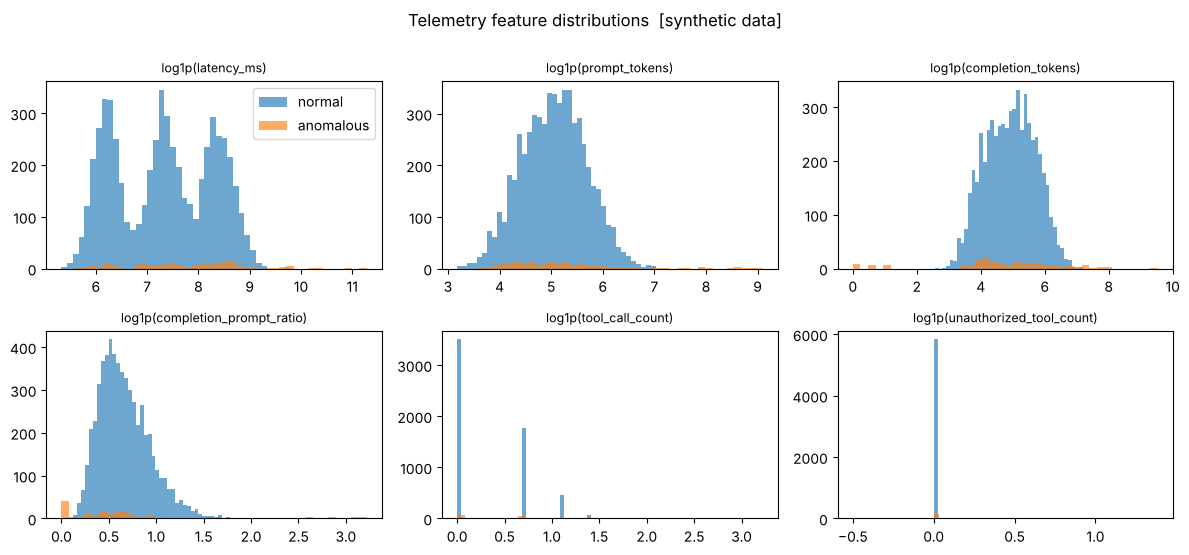

In [35]:
# EDA: missing values, outliers, distributions
print("missing values:", TEL[FEATURES].isna().sum().to_dict())
q1, q3 = TEL[FEATURES].quantile(.25), TEL[FEATURES].quantile(.75); iqr = q3 - q1
outl = ((TEL[FEATURES] < q1 - 1.5 * iqr) | (TEL[FEATURES] > q3 + 1.5 * iqr)).sum()
print("rows outside 1.5*IQR per feature:", outl.to_dict())
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
for ax, f in zip(axes.ravel(), FEATURES):
    x = np.log1p(TEL[f])
    if LABELS_AVAILABLE:
        ax.hist(x[TEL.is_anomaly == 0], bins=40, alpha=.65, label="normal"); ax.hist(x[TEL.is_anomaly == 1], bins=40, alpha=.65, label="anomalous")
    else:
        ax.hist(x, bins=40)
    ax.set_title(f"log1p({f})", fontsize=9)
axes[0, 0].legend(); plt.suptitle(f"Telemetry feature distributions  [{AD['data_origin']} data]", y=1.0); plt.tight_layout()
plt.savefig(REP_VIZ / "ad_feature_distributions.png", dpi=130); plt.show()

In [36]:
# Split, preprocessing (fit on train only), Isolation Forest tuning
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

if LABELS_AVAILABLE:
    tr_i, rest_i = train_test_split(TEL.index, test_size=0.30, stratify=TEL.is_anomaly, random_state=SEED)
    va_i, te_i = train_test_split(rest_i, test_size=0.50, stratify=TEL.loc[rest_i, "is_anomaly"], random_state=SEED)
else:
    tr_i, rest_i = train_test_split(TEL.index, test_size=0.30, random_state=SEED)
    va_i, te_i = train_test_split(rest_i, test_size=0.50, random_state=SEED)
TR, VA, TE = TEL.loc[tr_i], TEL.loc[va_i], TEL.loc[te_i]
print({"train": len(TR), "val": len(VA), "test": len(TE)})

preproc = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value=0)),
                    ("log1p", FunctionTransformer(np.log1p, validate=False)),
                    ("scale", RobustScaler())])
Xtr = preproc.fit_transform(TR[FEATURES]); Xva = preproc.transform(VA[FEATURES]); Xte = preproc.transform(TE[FEATURES])   # fit on TRAIN only

def fit_if(X, n_estimators, max_samples, contamination, seed=SEED):
    return IsolationForest(n_estimators=n_estimators, max_samples=max_samples, contamination=contamination,
                           random_state=seed, n_jobs=-1).fit(X)       # unsupervised: fit() never sees labels

def flag(model, X): return (model.predict(X) == -1).astype(int)

def prf(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"precision": float(precision_score(y, pred, zero_division=0)), "recall": float(recall_score(y, pred, zero_division=0)),
            "f1": float(f1_score(y, pred, zero_division=0)), "fpr": float(fp / max(fp + tn, 1)), "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn)}

if LABELS_AVAILABLE:
    grid = []
    for ne in (100, 300):
        for ms in ("auto", 256, 0.5):
            for cont in ("auto", 0.01, 0.02, 0.03, 0.05, 0.08):
                m = fit_if(Xtr, ne, ms, cont)
                grid.append({"n_estimators": ne, "max_samples": ms, "contamination": cont, **prf(VA.is_anomaly.values, flag(m, Xva))})
    G = pd.DataFrame(grid).assign(_ms=lambda d: d.max_samples.astype(str)).sort_values(["f1", "fpr"], ascending=[False, True]).reset_index(drop=True)
    display(G.drop(columns="_ms").head(8).round(3))
    bestp = G.iloc[0]
    BEST = {"n_estimators": int(bestp.n_estimators), "max_samples": bestp.max_samples if isinstance(bestp.max_samples, str) else (float(bestp.max_samples) if bestp.max_samples < 1 else int(bestp.max_samples)),
            "contamination": bestp.contamination if isinstance(bestp.contamination, str) else float(bestp.contamination)}
    AD["tuning"] = {"grid_size": len(G), "selected": BEST, "selection_rule": "max validation F1, ties -> lower FPR",
                    "note": "labels are used ONLY to choose hyper-parameters on the validation split; fit() is unsupervised"}
    print("selected:", BEST)

{'train': 4200, 'val': 900, 'test': 900}


,n_estimators,max_samples,contamination,precision,recall,f1,fpr,tp,fp,tn,fn
0,100,0.5,0.02,0.938,0.577,0.714,0.001,15,1,873,11
1,300,0.5,0.02,0.938,0.577,0.714,0.001,15,1,873,11
2,300,0.5,0.03,0.606,0.769,0.678,0.015,20,13,861,6
3,100,0.5,0.03,0.541,0.769,0.635,0.019,20,17,857,6
4,100,0.5,auto,0.438,0.808,0.568,0.031,21,27,847,5
5,300,0.5,auto,0.444,0.769,0.563,0.029,20,25,849,6
6,100,0.5,0.01,1.000,0.385,0.556,0.000,10,0,874,16
7,300,auto,0.02,0.619,0.500,0.553,0.009,13,8,866,13


selected: {'n_estimators': 100, 'max_samples': 0.5, 'contamination': 0.02}


In [37]:
# Final model, single test evaluation, per-scenario recall, stability, manual review
if LABELS_AVAILABLE:
    if_model = fit_if(Xtr, **BEST)
    pred_te = flag(if_model, Xte); score_te = -if_model.decision_function(Xte)       # higher = more anomalous
    y_te = TE.is_anomaly.values.astype(int)
    AD["test"] = {**prf(y_te, pred_te), "roc_auc": float(roc_auc_score(y_te, score_te)), "pr_auc": float(average_precision_score(y_te, score_te)),
                  "n": int(len(y_te)), "n_anomalies": int(y_te.sum())}
    AD["val"] = prf(VA.is_anomaly.values.astype(int), flag(if_model, Xva))
    sc = TE.assign(pred=pred_te)[TE.is_anomaly == 1].groupby("scenario").pred.agg(["mean", "size"]).rename(columns={"mean": "recall", "size": "n"})
    AD["test_recall_by_scenario"] = sc.reset_index().to_dict("records")
    AD["scores"] = {"test": (y_te, score_te)}
    display(pd.Series(AD["test"]).to_frame("test").T.round(3)); print("recall by injected scenario:"); display(sc.round(3))

    # stability: refit 5 times on a random 80% of train
    runs, flagged = [], []
    for k in range(5):
        sub = np.random.default_rng(100 + k).choice(len(Xtr), int(0.8 * len(Xtr)), replace=False)
        mk = fit_if(Xtr[sub], **BEST, seed=100 + k); pk = flag(mk, Xte)
        runs.append(prf(y_te, pk)["f1"]); flagged.append(set(np.where(pk == 1)[0]))
    jac = [len(a & b) / max(len(a | b), 1) for i, a in enumerate(flagged) for b in flagged[i + 1:]]
    AD["stability"] = {"f1_mean": float(np.mean(runs)), "f1_std": float(np.std(runs)), "flagged_set_jaccard_mean": float(np.mean(jac)), "n_refits": 5}
    print("stability:", {k: round(v, 3) if isinstance(v, float) else v for k, v in AD["stability"].items()})

    top = TE.assign(anomaly_score=score_te, flagged=pred_te).sort_values("anomaly_score", ascending=False).head(12)
    print("manual-review view: 12 highest-scoring test rows"); display(top[["scenario", "latency_ms", "prompt_tokens", "completion_tokens", "tool_call_count", "unauthorized_tool_count", "anomaly_score", "flagged"]].round(2))
    fp_rows = TE.assign(anomaly_score=score_te, flagged=pred_te)[(pred_te == 1) & (y_te == 0)].head(8)
    print("false positives (normal rows flagged), first 8:"); display(fp_rows[["agent_profile", "latency_ms", "prompt_tokens", "completion_tokens", "tool_call_count", "anomaly_score"]].round(2))
else:
    if_model = fit_if(Xtr, 200, "auto", "auto")
    score_all = -if_model.decision_function(Xte)
    AD["unlabeled"] = {"flagged_fraction_default_offset": float(flag(if_model, Xte).mean()),
                       "score_quantiles": {str(q): float(np.quantile(score_all, q)) for q in (.5, .9, .99)}}
    print("No labels: review score distribution and flagged rows manually.", AD["unlabeled"])
RESULTS["anomaly_detection"] = {k: v for k, v in AD.items() if k != "scores"}
set_status("anomaly_detection", "COMPLETED" if AD["data_origin"] == "real" else "PARTIAL",
           "" if AD["data_origin"] == "real" else "trained and evaluated on SYNTHETIC telemetry only (no real telemetry exists yet)")

,precision,recall,f1,fpr,tp,fp,tn,fn,roc_auc,pr_auc,n,n_anomalies
test,0.941,0.64,0.762,0.001,16.0,1.0,874.0,9.0,0.95,0.808,900.0,25.0


recall by injected scenario:


,recall,n
scenario,,
empty_response,1.000,6
high_latency,0.000,3
mild_latency,0.000,4
prompt_stuffing,1.000,2
token_explosion,0.667,3
tool_storm,0.667,3
unauthorized_tool,1.000,4


stability: {'f1_mean': 0.78, 'f1_std': 0.031, 'flagged_set_jaccard_mean': 0.836, 'n_refits': 5}
manual-review view: 12 highest-scoring test rows


,scenario,latency_ms,prompt_tokens,completion_tokens,tool_call_count,unauthorized_tool_count,anomaly_score,flagged
4685,token_explosion,1740.96,64,1096,1,0,0.10,1
3870,unauthorized_tool,2018.88,287,186,2,2,0.08,1
1942,empty_response,1819.58,198,0,0,0,0.07,1
5514,empty_response,5021.40,260,0,0,0,0.07,1
1744,unauthorized_tool,554.28,127,38,2,2,0.07,1
784,empty_response,5924.14,112,1,0,0,0.06,1
5900,tool_storm,3870.41,184,248,21,0,0.06,1
671,unauthorized_tool,857.37,368,131,1,1,0.05,1
1202,prompt_stuffing,563.63,2878,67,0,0,0.05,1
4609,empty_response,4519.34,403,1,1,0,0.05,1


false positives (normal rows flagged), first 8:


,agent_profile,latency_ms,prompt_tokens,completion_tokens,tool_call_count,anomaly_score
4282,small_fast,251.75,293,52,3,0.01


STATUS  anomaly_detection                  PARTIAL  trained and evaluated on SYNTHETIC telemetry only (no real telemetry exists yet)


## 09. Comparing models

Each model family is compared on its own metrics. The three components solve different problems, so I don't rank them against each other.

In [38]:
# Prompt-injection: baseline vs shortcut check vs DistilBERT
def pi_row(name):
    m = PI["metrics"].get(name)
    if not m: return {"model": name, "status": "NOT RUN"}
    t, v = m["test"], m["val"]
    return {"model": name, "status": "ran", "val_pr_auc": v.get("pr_auc"), "test_f1": t["f1"], "test_precision": t["precision"], "test_recall": t["recall"],
            "test_fpr": t["fpr"], "test_fnr": t["fnr"], "test_roc_auc": t.get("roc_auc"), "latency_mean_ms": m.get("latency", {}).get("mean_ms")}
PI_TABLE = pd.DataFrame([pi_row(n) for n in ("length_only_shortcut", "tfidf_lr", "distilbert")])
display(PI_TABLE.round(4))

if "distilbert" in PI["metrics"] and "tfidf_lr" in PI["metrics"]:
    d, b = PI["metrics"]["distilbert"], PI["metrics"]["tfidf_lr"]
    gain = d["val"]["pr_auc"] - b["val"]["pr_auc"]
    PI_SELECTED = "distilbert" if gain > 0 else "tfidf_lr"
    print(f"validation PR-AUC gain of DistilBERT over baseline: {gain:+.4f}  ->  selected = {PI_SELECTED}")
    print("DistilBERT mean latency %.1f ms vs baseline %.2f ms" % (d["latency"]["mean_ms"], b["latency"]["mean_ms"]))
elif "tfidf_lr" in PI["metrics"]:
    PI_SELECTED = "tfidf_lr"; print("DistilBERT did not run -> only the baseline is available; selected = tfidf_lr (baseline).")
else:
    PI_SELECTED = None
RESULTS["prompt_injection"] = {"models": {k: {kk: vv for kk, vv in v.items()} for k, v in PI["metrics"].items() if isinstance(v, dict)},
                               "loso_tfidf_lr": PI["metrics"].get("loso_tfidf_lr"), "selected": PI_SELECTED}
if "tfidf_lr" in PI["metrics"] and "prompt_injection" not in STATUS:
    set_status("prompt_injection", "PARTIAL", "baseline only; trained/evaluated on BIPIA only (stand-alone prompt datasets and DistilBERT unavailable in this run)"
               if not HF_PROMPT_RAW else "baseline only; DistilBERT unavailable in this run")
elif "distilbert" in PI["metrics"]:
    set_status("prompt_injection", "COMPLETED" if HF_PROMPT_RAW else "PARTIAL", "" if HF_PROMPT_RAW else "BIPIA only")

,model,status,val_pr_auc,test_f1,test_precision,test_recall,test_fpr,test_fnr,test_roc_auc,latency_mean_ms
0,length_only_shortcut,ran,0.5916,0.6639,0.5244,0.9045,0.8202,0.0955,0.5975,NaN
1,tfidf_lr,ran,0.9214,0.8009,0.6926,0.9494,0.4213,0.0506,0.8912,0.6486
2,distilbert,NOT RUN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


DistilBERT did not run -> only the baseline is available; selected = tfidf_lr (baseline).
STATUS  prompt_injection                   PARTIAL  baseline only; trained/evaluated on BIPIA only (stand-alone prompt datasets and DistilBERT unavailable in this run)


## 10. Plots

Saved in `reports/visualizations`. If a model didn't run, its plot is simply missing.

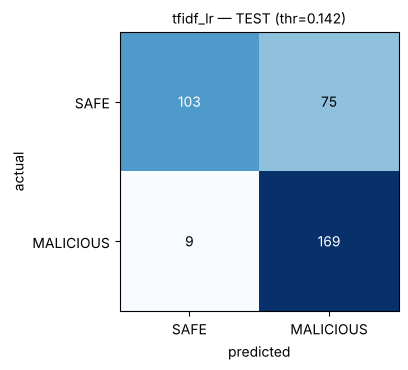

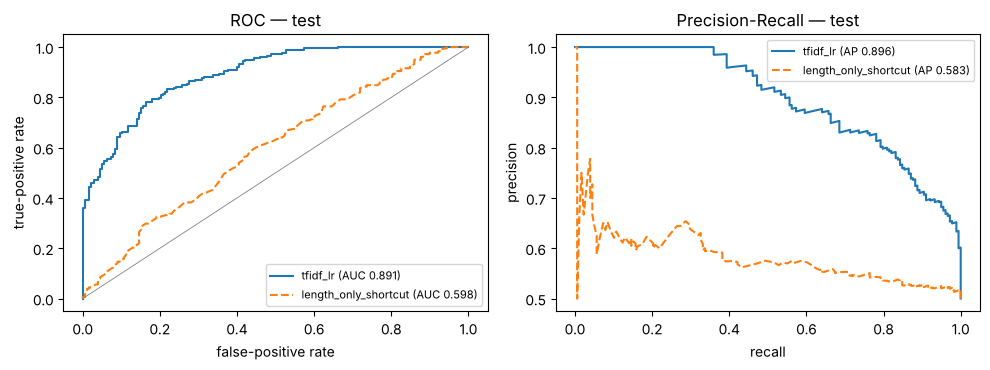

In [39]:
# Confusion matrices, ROC and PR curves
def plot_cm(ax, y, s, thr, title):
    cm = confusion_matrix(y, (np.asarray(s) >= thr).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues"); ax.set_title(title, fontsize=10)
    ax.set_xticks([0, 1], ["SAFE", "MALICIOUS"]); ax.set_yticks([0, 1], ["SAFE", "MALICIOUS"]); ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, int(v), ha="center", va="center", color="white" if v > cm.max() / 2 else "black")

models = [m for m in ("tfidf_lr", "distilbert") if m in PI["metrics"]]
if models:
    fig, axes = plt.subplots(1, len(models), figsize=(4.4 * len(models), 3.8), squeeze=False)
    for ax, m in zip(axes[0], models):
        y, s = PI["scores"][m]["test"]; plot_cm(ax, y, s, PI["metrics"][m]["threshold"], f"{m} — TEST (thr={PI['metrics'][m]['threshold']:.3f})")
    plt.tight_layout(); plt.savefig(REP_VIZ / "pi_confusion_matrices.png", dpi=130); plt.show()

    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    for m in models + (["length_only_shortcut"] if "length_only_shortcut" in PI["scores"] else []):
        y, s = PI["scores"][m]["test"]
        fpr_, tpr_, _ = roc_curve(y, s); pr_, rc_, _ = precision_recall_curve(y, s)
        ax[0].plot(fpr_, tpr_, label=f"{m} (AUC {roc_auc_score(y, s):.3f})", ls="--" if "shortcut" in m else "-")
        ax[1].plot(rc_, pr_, label=f"{m} (AP {average_precision_score(y, s):.3f})", ls="--" if "shortcut" in m else "-")
    ax[0].plot([0, 1], [0, 1], color="grey", lw=.6); ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("true-positive rate"); ax[0].set_title("ROC — test"); ax[0].legend(fontsize=8)
    ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-Recall — test"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(REP_VIZ / "pi_roc_pr.png", dpi=130); plt.show()

MiniLM did not run — similarity plots omitted.


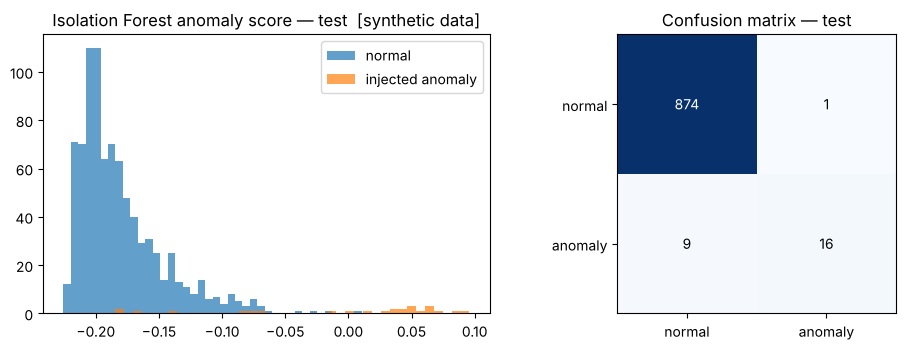

In [40]:
# Similarity score distributions (only if MiniLM ran)
if RUN_STS and "scores" in STS:
    gold, cos = STS["scores"]["test"]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].hist(cos[gold >= CONFIG["STS_POSITIVE_GOLD_CUTOFF"]], bins=30, alpha=.7, label="gold ≥ cutoff (similar)")
    ax[0].hist(cos[gold < CONFIG["STS_POSITIVE_GOLD_CUTOFF"]], bins=30, alpha=.7, label="gold < cutoff")
    ax[0].axvline(STS["similarity_threshold"], color="k", ls="--", label="threshold"); ax[0].set_title("Cosine similarity — STS-B test"); ax[0].legend(fontsize=8)
    ax[1].scatter(gold, cos, s=4, alpha=.35); ax[1].set_xlabel("gold score (0-5)"); ax[1].set_ylabel("cosine"); ax[1].set_title(f"Spearman {STS['test']['spearman']:.3f}")
    plt.tight_layout(); plt.savefig(REP_VIZ / "sts_score_distributions.png", dpi=130); plt.show()
else:
    print("MiniLM did not run — similarity plots omitted.")

# Anomaly score distribution
if LABELS_AVAILABLE and "scores" in AD:
    y, s = AD["scores"]["test"]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].hist(s[y == 0], bins=40, alpha=.7, label="normal"); ax[0].hist(s[y == 1], bins=40, alpha=.7, label="injected anomaly")
    ax[0].set_title(f"Isolation Forest anomaly score — test  [{AD['data_origin']} data]"); ax[0].legend()
    cm_ = confusion_matrix(y, flag(if_model, Xte), labels=[0, 1]); ax[1].imshow(cm_, cmap="Blues"); ax[1].set_title("Confusion matrix — test")
    ax[1].set_xticks([0, 1], ["normal", "anomaly"]); ax[1].set_yticks([0, 1], ["normal", "anomaly"])
    for (i, j), v in np.ndenumerate(cm_): ax[1].text(j, i, int(v), ha="center", va="center", color="white" if v > cm_.max() / 2 else "black")
    plt.tight_layout(); plt.savefig(REP_VIZ / "ad_scores_and_confusion.png", dpi=130); plt.show()

## 11. Exporting models

Only writes what was actually produced, and hashes every file into `manifest.json`. The anomaly model is marked `production_ready: false` while it's trained on synthetic data.

In [41]:
# Export
EXPORTED = []
def _write_json(p, obj): Path(p).parent.mkdir(parents=True, exist_ok=True); Path(p).write_text(json.dumps(jsonable(obj), indent=2)); EXPORTED.append(Path(p))

# prompt injection
if "tfidf_lr" in PI["metrics"]:
    pi_dir = ARTIFACTS / "prompt_injection"; pi_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump(base_pipe, pi_dir / "baseline_tfidf_lr.joblib"); EXPORTED.append(pi_dir / "baseline_tfidf_lr.joblib")
    trained_on = sorted(PI_ALL.source.unique())
    _write_json(pi_dir / "config.json", {
        "task": "prompt_injection_detection", "labels": {"0": "SAFE", "1": "MALICIOUS"}, "model_version": CONFIG["MODEL_VERSION"],
        "selected_model": PI_SELECTED, "created_utc": now_iso(), "seed": SEED,
        "models": {"tfidf_lr": {"file": "baseline_tfidf_lr.joblib", "threshold": PI["metrics"]["tfidf_lr"]["threshold"]},
                   **({"distilbert": {"model_dir": "model", "tokenizer_dir": "tokenizer", "threshold": PI["metrics"]["distilbert"]["threshold"],
                                       "max_len": CONFIG["PI_DISTILBERT"]["max_len"]}} if "distilbert" in PI["metrics"] else {})},
        "score_semantics": "malicious_score is a model ranking score compared against `threshold`; it is NOT a calibrated probability of malicious intent.",
        "trained_on_sources": trained_on, "stand_alone_prompt_sources_used": bool(HF_PROMPT_RAW),
        "production_ready": False,
        "warnings": ([] if HF_PROMPT_RAW else ["Trained on BIPIA (indirect injection in emails/tables/code) ONLY. It has never seen stand-alone user prompts, "
                                              "jailbreaks or system-prompt extraction attempts. Do not use as a sole security control."]),
        "test_metrics_ref": "reports/evaluation/metrics.json",
    })

# semantic similarity
if RUN_STS and "similarity_threshold" in STS:
    ss_dir = ARTIFACTS / "semantic_similarity"; (ss_dir / "model").mkdir(parents=True, exist_ok=True)
    minilm.save(str(ss_dir / "model"))
    _write_json(ss_dir / "config.json", {"model": CONFIG["HF_MINILM"], "revision": STS["revision"], "similarity_threshold": STS["similarity_threshold"],
                                          "threshold_selection": f"max-F1 on STS-B train, gold>={STS['positive_gold_cutoff']} = similar",
                                          "linear_score_calibration": STS["calibration_linear_fit"], "model_version": CONFIG["MODEL_VERSION"],
                                          "note": "semantic closeness only — not a factual-correctness check"})

# anomaly detection
ad_dir = ARTIFACTS / "anomaly_detection"; ad_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(if_model, ad_dir / "model.joblib"); joblib.dump(preproc, ad_dir / "preprocessing.joblib"); EXPORTED += [ad_dir / "model.joblib", ad_dir / "preprocessing.joblib"]
_write_json(ad_dir / "config.json", {"features": FEATURES, "model_version": CONFIG["MODEL_VERSION"], "isolation_forest_params": BEST if LABELS_AVAILABLE else {"n_estimators": 200},
                                      "data_origin": AD["data_origin"], "production_ready": AD["data_origin"] == "real",
                                      "score_semantics": "score = -decision_function (higher = more unusual). Unusual != malicious.",
                                      "excluded_prd_features": ["retry_count", "request_frequency", "error_count", "failed_tool_calls"],
                                      "excluded_reason": "not collected by the current backend (see the notes in section 08)",
                                      "warnings": ["Trained on SYNTHETIC telemetry; retrain on real AgentShield telemetry before relying on it."] if AD["data_origin"] != "real" else [],
                                      "created_utc": now_iso()})

# manifest
def git_head():
    try:
        import subprocess
        return subprocess.run(["git", "rev-parse", "HEAD"], cwd=ML_ROOT, capture_output=True, text=True, timeout=5).stdout.strip() or None
    except Exception: return None
files = [p for p in ARTIFACTS.rglob("*") if p.is_file() and "checkpoints" not in p.parts]
_write_json(ARTIFACTS / "manifest.json", {"created_utc": now_iso(), "repo_commit": git_head(), "environment": ENV_INFO, "model_version": CONFIG["MODEL_VERSION"],
                                          "files": {str(p.relative_to(ARTIFACTS)): {"sha256": sha256_file(p), "bytes": p.stat().st_size} for p in files if p.name != "manifest.json"}})
print("exported:")
for p in sorted(files): print("  ", p.relative_to(ML_ROOT))

exported:
   artifacts/anomaly_detection/config.json
   artifacts/anomaly_detection/model.joblib
   artifacts/anomaly_detection/preprocessing.joblib
   artifacts/prompt_injection/baseline_tfidf_lr.joblib
   artifacts/prompt_injection/config.json


## 12. Final report

Built entirely from the results collected above and saved as `reports/evaluation/ML_REPORT.md` and `metrics.json`.

In [42]:
# Report
def fmt(x, nd=3):
    return "n/a" if x is None or (isinstance(x, float) and math.isnan(x)) else (f"{x:.{nd}f}" if isinstance(x, (float, np.floating)) else str(x))

L = []
L += [f"# AgentShield ML — Run Report", f"_Generated {now_iso()} · seed {SEED} · model_version {CONFIG['MODEL_VERSION']}_", ""]
L += ["## Run status", "", "| Component | State | Reason |", "|---|---|---|"]
for k, v in STATUS.items(): L.append(f"| {k} | **{v['state']}** | {v['reason'] or '—'} |")
L += ["", "Environment: " + ", ".join(f"{k}={v}" for k, v in ENV_INFO.items() if v is not None), ""]

L += ["## Data sources", "", "| Source | Status | Licence | Revision | Accessed (UTC) |", "|---|---|---|---|---|"]
for s in SOURCES: L.append(f"| {s['source_key']} | {s.get('status')} | {s.get('license', '—')} | `{str(s.get('revision', '—'))[:12]}` | {s['access_date_utc']} |")
for s in SOURCES:
    for n in s.get("third_party_notices", []) + s.get("unverified_notes", []): L.append(f"\n- {s['source_key']}: {n}")
L.append("")

if len(PI_ALL):
    L += ["## Prompt-injection dataset", "", "| Split | SAFE | MALICIOUS | total |", "|---|---:|---:|---:|"]
    for sp in ("train", "val", "test"):
        c = PI_ALL[PI_ALL.split == sp].label.value_counts(); L.append(f"| {sp} | {c.get(0, 0)} | {c.get(1, 0)} | {int(c.sum())} |")
    L += ["", "Cleaning log: `" + json.dumps(jsonable(CLEAN_LOG.get("bipia_cleaning", {}))) + "`", "",
          "Leakage checks (all must be 0): exact=`" + json.dumps(CLEAN_LOG["leakage_report"]["exact_overlap"]) + "`, groups=`" + json.dumps(CLEAN_LOG["leakage_report"]["group_overlap"]) +
          "`, attack-category=`" + json.dumps(CLEAN_LOG["leakage_report"]["bipia_attack_category_overlap"]) + "`", ""]
    L += ["### Prompt-injection results (test split, threshold chosen on validation)", "", "| Model | F1 | Precision | Recall | FPR | FNR | ROC-AUC | mean latency ms |", "|---|---:|---:|---:|---:|---:|---:|---:|"]
    for n in ("length_only_shortcut", "tfidf_lr", "distilbert"):
        m = PI["metrics"].get(n)
        L.append(f"| {n} | " + " | ".join(fmt(x) for x in ([m["test"]["f1"], m["test"]["precision"], m["test"]["recall"], m["test"]["fpr"], m["test"]["fnr"], m["test"].get("roc_auc"), m.get("latency", {}).get("mean_ms")] if m else [None]*7)) + " |" if m else f"| {n} | NOT RUN | | | | | | |")
    if PI["metrics"].get("loso_tfidf_lr"):
        L += ["", "Leave-one-source-group-out (baseline):", "", "| held-out | F1 | recall | FPR | ROC-AUC |", "|---|---:|---:|---:|---:|"]
        for r in PI["metrics"]["loso_tfidf_lr"]: L.append(f"| {r['held_out']} | {fmt(r.get('f1'))} | {fmt(r.get('recall'))} | {fmt(r.get('fpr'))} | {fmt(r.get('roc_auc'))} |")
    L.append("")

L += ["## Semantic similarity", ""]
if "test" in STS:
    t = STS["test"]; tm = t["threshold_metrics"]
    L += [f"STS-B test (n={t['n']}): Pearson {fmt(t['pearson'])}, Spearman {fmt(t['spearman'])}, MSE(raw map) {fmt(t['mse_raw_map'])}, MAE(raw map) {fmt(t['mae_raw_map'])}, "
          f"MSE(calibrated) {fmt(t['mse_calibrated'])}, MAE(calibrated) {fmt(t['mae_calibrated'])}.",
          f"Threshold {fmt(STS['similarity_threshold'], 4)}: precision {fmt(tm['precision'])}, recall {fmt(tm['recall'])}, F1 {fmt(tm['f1'])}, FPR {fmt(tm['fpr'])}.",
          f"Author-written project pairs: agreement with author labels {fmt(STS['project_pairs']['agreement_with_author_labels'])} over {STS['project_pairs']['n']} pairs (illustrative, not a benchmark)."]
else: L.append("**Not run in this execution** (see status table). No similarity metrics are reported.")

L += ["", "## Anomaly detection", "", f"**Data origin: {AD['data_origin'].upper()}**" + (" — metrics below describe a pipeline check on injected anomalies, not real-world performance." if AD['data_origin'] == 'synthetic' else ""), ""]
if "test" in AD:
    t = AD["test"]
    L += [f"Test (n={t['n']}, {t['n_anomalies']} anomalies): precision {fmt(t['precision'])}, recall {fmt(t['recall'])}, F1 {fmt(t['f1'])}, FPR {fmt(t['fpr'])}, ROC-AUC {fmt(t['roc_auc'])}, PR-AUC {fmt(t['pr_auc'])}.",
          f"Stability over 5 refits: F1 {fmt(AD['stability']['f1_mean'])} ± {fmt(AD['stability']['f1_std'])}, flagged-set Jaccard {fmt(AD['stability']['flagged_set_jaccard_mean'])}.", "",
          "| Injected scenario | recall | n (test) |", "|---|---:|---:|"] + [f"| {r['scenario']} | {fmt(r['recall'])} | {r['n']} |" for r in AD["test_recall_by_scenario"]]
    L.append("\nPer-scenario counts are very small; treat per-scenario recall as anecdotal.")

L += ["", "## Blockers recorded during this run", ""] + ([f"- {b}" for b in dict.fromkeys(BLOCKERS)] or ["- none"])
L += ["", "## Limitations (always apply)", "",
      "- Model scores are rankings against a threshold, not probabilities of malicious intent; keep deterministic security checks alongside ML.",
      "- Semantic similarity does not establish factual correctness.",
      "- Isolation Forest flags *unusual* behaviour, not confirmed malicious activity.",
      "- BIPIA labels are defined by construction (inserted instruction = MALICIOUS); results on BIPIA do not transfer automatically to other attack styles.",
      "- BIPIA-derived data includes CC BY-SA 4.0 material; the processed data folder is git-ignored by default.", "",
      "## Reproducibility", "",
      f"Seed {SEED}; BIPIA pinned to `{CONFIG['BIPIA_COMMIT']}`; Hub revisions pinned in `datasets/metadata/sources_lock.json`; split manifest in `datasets/metadata/prompt_injection_split_manifest.json`. "
      "Run the notebook top to bottom (see `ml/README.md`)."]
REPORT_MD = "\n".join(L)
(REP_EVAL / "ML_REPORT.md").write_text(REPORT_MD)
(REP_EVAL / "metrics.json").write_text(json.dumps(jsonable({"status": STATUS, "blockers": list(dict.fromkeys(BLOCKERS)), "results": RESULTS, "sources": SOURCES,
                                                             "cleaning": CLEAN_LOG, "environment": ENV_INFO, "config": CONFIG}), indent=2, default=str))
from IPython.display import Markdown, display as _d
_d(Markdown(REPORT_MD))

# AgentShield ML — Run Report
_Generated 2026-11-05T13:20:34+00:00 · seed 42 · model_version 0.1.0_

## Run status

| Component | State | Reason |
|---|---|---|
| prompt_injection_distilbert | **SKIPPED** | missing: torch, transformers, Hub access |
| semantic_similarity | **SKIPPED** | missing: sentence-transformers, Hub access, STS-B data |
| anomaly_detection | **PARTIAL** | trained and evaluated on SYNTHETIC telemetry only (no real telemetry exists yet) |
| prompt_injection | **PARTIAL** | baseline only; trained/evaluated on BIPIA only (stand-alone prompt datasets and DistilBERT unavailable in this run) |

Environment: python=3.12.3, platform=Linux-6.18.44-fc-v236-x86_64-with-glibc2.39, datasets=5.1.0, sklearn=1.9.1, numpy=2.5.4, pandas=3.0.6, device=cpu, amp=False, huggingface_hub_reachable=False

## Data sources

| Source | Status | Licence | Revision | Accessed (UTC) |
|---|---|---|---|---|
| bipia | loaded | MIT | `a004b69ec0dd` | 2026-11-05T13:20:15+00:00 |
| deepset_prompt_injections | blocked | — | `—` | 2026-11-05T13:20:15+00:00 |
| neuralchemy_prompt_injection | blocked | — | `—` | 2026-11-05T13:20:15+00:00 |
| glue_stsb | blocked | — | `—` | 2026-11-05T13:20:15+00:00 |

- bipia: WikiTableQuestions (table task contexts): CC BY-SA 4.0 — attribution + share-alike apply to derived data

- bipia: Email contexts come from OpenAI Evals and code contexts from Stack Exchange per the BIPIA README; their licences are NOT stated in the repo and were not verified here — confirm before redistributing any dataset derived from BIPIA.

## Prompt-injection dataset

| Split | SAFE | MALICIOUS | total |
|---|---:|---:|---:|
| train | 292 | 292 | 584 |
| val | 74 | 74 | 148 |
| test | 178 | 178 | 356 |

Cleaning log: `{"dropped_empty_or_corrupted_contexts": 0, "dropped_duplicate_contexts_within_split": 310, "dropped_train_contexts_also_in_test": 11, "dropped_train_contexts_near_duplicate_of_test": 18, "near_duplicate_threshold": 0.8, "dropped_train_attack_categories_also_in_test": ["text:Language Translation"]}`

Leakage checks (all must be 0): exact=`{"train&val": 0, "train&test": 0, "val&test": 0}`, groups=`{"train&val": 0, "train&test": 0, "val&test": 0}`, attack-category=`{"train&val": 0, "train&test": 0, "val&test": 0}`

### Prompt-injection results (test split, threshold chosen on validation)

| Model | F1 | Precision | Recall | FPR | FNR | ROC-AUC | mean latency ms |
|---|---:|---:|---:|---:|---:|---:|---:|
| length_only_shortcut | 0.664 | 0.524 | 0.904 | 0.820 | 0.096 | 0.598 | n/a |
| tfidf_lr | 0.801 | 0.693 | 0.949 | 0.421 | 0.051 | 0.891 | 0.649 |
| distilbert | NOT RUN | | | | | | |

Leave-one-source-group-out (baseline):

| held-out | F1 | recall | FPR | ROC-AUC |
|---|---:|---:|---:|---:|
| bipia_code | 0.667 | 1.000 | 1.000 | 0.768 |
| bipia_text | 0.106 | 0.056 | 0.005 | 0.746 |

## Semantic similarity

**Not run in this execution** (see status table). No similarity metrics are reported.

## Anomaly detection

**Data origin: SYNTHETIC** — metrics below describe a pipeline check on injected anomalies, not real-world performance.

Test (n=900, 25 anomalies): precision 0.941, recall 0.640, F1 0.762, FPR 0.001, ROC-AUC 0.950, PR-AUC 0.808.
Stability over 5 refits: F1 0.780 ± 0.031, flagged-set Jaccard 0.836.

| Injected scenario | recall | n (test) |
|---|---:|---:|
| empty_response | 1.000 | 6 |
| high_latency | 0.000 | 3 |
| mild_latency | 0.000 | 4 |
| prompt_stuffing | 1.000 | 2 |
| token_explosion | 0.667 | 3 |
| tool_storm | 0.667 | 3 |
| unauthorized_tool | 1.000 | 4 |

Per-scenario counts are very small; treat per-scenario recall as anecdotal.

## Blockers recorded during this run

- [data:deepset_prompt_injections] blocked: huggingface.co not reachable from this environment
- [data:neuralchemy_prompt_injection] blocked: huggingface.co not reachable from this environment
- [data:glue_stsb] blocked: huggingface.co not reachable from this environment
- [prompt_injection_distilbert] SKIPPED: missing: torch, transformers, Hub access
- [semantic_similarity] SKIPPED: missing: sentence-transformers, Hub access, STS-B data
- [anomaly_detection] PARTIAL: trained and evaluated on SYNTHETIC telemetry only (no real telemetry exists yet)
- [prompt_injection] PARTIAL: baseline only; trained/evaluated on BIPIA only (stand-alone prompt datasets and DistilBERT unavailable in this run)

## Limitations (always apply)

- Model scores are rankings against a threshold, not probabilities of malicious intent; keep deterministic security checks alongside ML.
- Semantic similarity does not establish factual correctness.
- Isolation Forest flags *unusual* behaviour, not confirmed malicious activity.
- BIPIA labels are defined by construction (inserted instruction = MALICIOUS); results on BIPIA do not transfer automatically to other attack styles.
- BIPIA-derived data includes CC BY-SA 4.0 material; the processed data folder is git-ignored by default.

## Reproducibility

Seed 42; BIPIA pinned to `a004b69ec0dd446e0afd461d98cb5e96e120a5d0`; Hub revisions pinned in `datasets/metadata/sources_lock.json`; split manifest in `datasets/metadata/prompt_injection_split_manifest.json`. Run the notebook top to bottom (see `ml/README.md`).